# Pola Kehadiran Perangkat dan Arus Kunjungan Antar-Kapanewon di D.I. Yogyakarta (Desember 2021 – Februari 2022)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arinevangelicaa/Rekdat-HumanMobility/blob/main/notebooks/human_mobility_analysis.ipynb)

---

### Identitas Kelompok — Proyek Rekayasa Data (Semester 5)
**Departemen Teknik Elektro dan Teknologi Informasi, Fakultas Teknik, Universitas Gadjah Mada**

1. **Arin Evangelica Patabang** — NIM: `24/534030/TK/59182`
2. **Nayla Thalita** — NIM: `24/535820/TK/59467`
3. **Arimbi Arum Sari** — NIM: `24/541867/TK/60129`
4. **Nabila Putri Barokah** — NIM: `24/541890/TK/60132`
5. **Stella Florencia Doulim** — NIM: `24/542739/TK/60285`

---

### Daftar Isi
* [1. Persiapan Lingkungan & Deteksi Google Colab](#sec-1)
* [2. Pemuatan Data & Validasi Integritas (ETL - Extract & Validate)](#sec-2)
* [3. Kamus Data & Dokumentasi Dua Sumber Data](#sec-3)
* [4. Pipeline Rekayasa Data: Star Schema & OLAP (Materi Week 8)](#sec-4)
* [5. Analisis RQ1: Pola Kehadiran Temporal](#sec-5)
* [6. Analisis RQ2: Arus Kunjungan Asal-Tujuan (OD Flows)](#sec-6)
* [7. Analisis RQ3: Normalisasi Sampel & Validasi Populasi BPS](#sec-7)
* [8. Analisis Spasial: Sebaran Kehadiran pada Grid 500m](#sec-8)
* [9. Kualitas Data, Mekanisme Supresi Privasi ($k=5$), & Limitasi](#sec-9)
* [10. Kesimpulan Sintesis & Rekomendasi Riset](#sec-10)

---


<a name="sec-1"></a>
## 1. Inisialisasi Lingkungan & Direktori
Pengecekan direktori dataset untuk memastikan kompatibilitas lingkungan lokal maupun Google Colab.

In [1]:
# 1.1 Deteksi lingkungan dan penyiapan dataset (lokal maupun Google Colab)
from pathlib import Path
import os
import zipfile
import urllib.request

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"[INFO] Lingkungan eksekusi: {'Google Colab' if IN_COLAB else 'Lokal / Jupyter'}")

REQUIRED_FILES = [
    "presence_kapanewon_hourly.csv",
    "presence_cell500m_daily.csv",
    "od_home_visits_kapanewon_monthly.csv",
    "od_origin_homes_monthly.csv",
    "home_maids_vs_population_kapanewon.csv",
    "validation_night_presence_kapanewon.csv",
    "tier1_summary.csv",
    "od_summary.csv",
]
REPO_DATA_URL = "https://github.com/arinevangelicaa/Rekdat-HumanMobility/archive/refs/heads/main.zip"

# Cari folder dataset yang lengkap. Jika notebook dibuka langsung lewat Colab,
# unduh arsip repo dan ambil folder dataset tanpa meminta CSV diunggah manual.
roots = [Path.cwd(), Path.cwd().parent, Path("/content")]
DATASET_DIR = None
for root in roots:
    candidate = root / "dataset"
    if all((candidate / name).is_file() for name in REQUIRED_FILES):
        DATASET_DIR = candidate.resolve()
        break

if DATASET_DIR is None and IN_COLAB:
    print("[INFO] Dataset lengkap belum ditemukan; mengunduh CSV dari repositori GitHub...")
    archive = Path("/content/human-mobility-repo.zip")
    urllib.request.urlretrieve(REPO_DATA_URL, archive)
    with zipfile.ZipFile(archive) as zf:
        match = next((n for n in zf.namelist() if n.endswith("/dataset/README.md")), None)
        if match is None:
            raise RuntimeError("Arsip GitHub tidak berisi dataset/README.md.")
        repo_root = match.split("/dataset/README.md")[0]
        for name in REQUIRED_FILES + ["README.md"]:
            member = f"{repo_root}/dataset/{name}"
            if member not in zf.namelist():
                raise RuntimeError(f"File dataset tidak ditemukan di repo: {name}")
            zf.extract(member, "/content")
        extracted = Path("/content") / repo_root / "dataset"
        target = Path("/content/dataset")
        if extracted.resolve() != target.resolve():
            import shutil
            if target.exists():
                shutil.rmtree(target)
            extracted.rename(target)
        archive.unlink(missing_ok=True)
    DATASET_DIR = Path("/content/dataset")

if DATASET_DIR is None:
    raise FileNotFoundError(
        "Dataset belum lengkap. Di Google Colab, jalankan ulang sel ini agar data "
        "diunduh dari GitHub. Untuk lokal, letakkan folder dataset sejajar dengan notebook."
    )

BASE_DIR = DATASET_DIR.parent
FIGURES_DIR = BASE_DIR / "outputs" / "figures"
TABLES_DIR = BASE_DIR / "outputs" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
print(f"[OK] Dataset: {DATASET_DIR}")
print(f"[OK] Output gambar: {FIGURES_DIR}")
print(f"[OK] Output tabel: {TABLES_DIR}")


[INFO] Lingkungan eksekusi: Lokal / Jupyter
[OK] Dataset: C:\UGM\Kuliah\Sem_5\Rekayasa Data\PROJECT AFTER UTS\dataset
[OK] Output gambar: C:\UGM\Kuliah\Sem_5\Rekayasa Data\PROJECT AFTER UTS\outputs\figures
[OK] Output tabel: C:\UGM\Kuliah\Sem_5\Rekayasa Data\PROJECT AFTER UTS\outputs\tables


### 1.2 Import Library dan Konfigurasi Visualisasi
Mengimpor pustaka analitik data (`pandas`, `numpy`) dan visualisasi data (`matplotlib`, `seaborn`). Pengaturan tema dibuat standar publikasi (300 DPI, tema putih bergaris (*whitegrid*), palet warna ramah mata, dan label Bahasa Indonesia).

In [2]:
# 1.2 Import Pustaka dan Pengaturan Estetika Visualisasi
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Format tampilan Pandas
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_rows', 20)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Konfigurasi gaya visualisasi Seaborn dan Matplotlib
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 15,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.autolayout': True
})
print("[OK] Library analitik berhasil dimuat dan styling visualisasi siap.")

[OK] Library analitik berhasil dimuat dan styling visualisasi siap.


<a name="sec-2"></a>
## 2. Pemuatan Data & Validasi Integritas (ETL: Extract & Validate)
Pada tahap **Extract**, kita memuat ke-8 berkas CSV dari dataset JogjaPulse Zenodo. Tahap **Validate** memastikan skema data sesuai, tidak ada duplikasi record, serta mendokumentasikan nilai supresi privasi ($k=5$).

In [3]:
# 2.1 Memuat Seluruh Berkas CSV Dataset
df_pres_kapanewon = pd.read_csv(os.path.join(DATASET_DIR, "presence_kapanewon_hourly.csv"))
df_pres_cell = pd.read_csv(os.path.join(DATASET_DIR, "presence_cell500m_daily.csv"))
df_od_visits = pd.read_csv(os.path.join(DATASET_DIR, "od_home_visits_kapanewon_monthly.csv"))
df_od_origin = pd.read_csv(os.path.join(DATASET_DIR, "od_origin_homes_monthly.csv"))
df_home_pop = pd.read_csv(os.path.join(DATASET_DIR, "home_maids_vs_population_kapanewon.csv"))
df_val_night = pd.read_csv(os.path.join(DATASET_DIR, "validation_night_presence_kapanewon.csv"))
df_tier1_sum = pd.read_csv(os.path.join(DATASET_DIR, "tier1_summary.csv"))
df_od_sum = pd.read_csv(os.path.join(DATASET_DIR, "od_summary.csv"))

print("[OK] Seluruh 8 file dataset berhasil dimuat ke memori.")

[OK] Seluruh 8 file dataset berhasil dimuat ke memori.


### 2.2 Pemeriksaan Dimensi & Struktur Setiap Tabel
Melihat dimensi (jumlah baris dan kolom) serta contoh 5 baris pertama data kehadiran per kapanewon per jam.

In [4]:
# 2.2 Ringkasan Dimensi Seluruh Dataset
inventory = [
    {"Nama File": "presence_kapanewon_hourly.csv", "Baris": f"{len(df_pres_kapanewon):,}", "Kolom": df_pres_kapanewon.shape[1], "Grain": "Kapanewon × Jam"},
    {"Nama File": "presence_cell500m_daily.csv", "Baris": f"{len(df_pres_cell):,}", "Kolom": df_pres_cell.shape[1], "Grain": "Grid Cell 500m × Hari"},
    {"Nama File": "od_home_visits_kapanewon_monthly.csv", "Baris": f"{len(df_od_visits):,}", "Kolom": df_od_visits.shape[1], "Grain": "Asal × Tujuan × Bulan"},
    {"Nama File": "od_origin_homes_monthly.csv", "Baris": f"{len(df_od_origin):,}", "Kolom": df_od_origin.shape[1], "Grain": "Asal Kapanewon × Bulan"},
    {"Nama File": "home_maids_vs_population_kapanewon.csv", "Baris": f"{len(df_home_pop):,}", "Kolom": df_home_pop.shape[1], "Grain": "Kapanewon (Agregat)"},
    {"Nama File": "validation_night_presence_kapanewon.csv", "Baris": f"{len(df_val_night):,}", "Kolom": df_val_night.shape[1], "Grain": "Kapanewon × Periode"},
    {"Nama File": "tier1_summary.csv", "Baris": f"{len(df_tier1_sum):,}", "Kolom": df_tier1_sum.shape[1], "Grain": "Produk Presence"},
    {"Nama File": "od_summary.csv", "Baris": f"{len(df_od_sum):,}", "Kolom": df_od_sum.shape[1], "Grain": "Produk OD"}
]
df_inventory = pd.DataFrame(inventory)
display(df_inventory)

print("\nContoh 5 Baris Teratas - presence_kapanewon_hourly.csv:")
display(df_pres_kapanewon.head(5))

,Nama File,Baris,Kolom,Grain
0,presence_kapanewon_hourly.csv,"230,418",8,Kapanewon × Jam
1,presence_cell500m_daily.csv,"183,548",7,Grid Cell 500m × Hari
2,od_home_visits_kapanewon_monthly.csv,"9,894",11,Asal × Tujuan × Bulan
3,od_origin_homes_monthly.csv,390,8,Asal Kapanewon × Bulan
4,home_maids_vs_population_kapanewon.csv,78,5,Kapanewon (Agregat)
5,validation_night_presence_kapanewon.csv,156,7,Kapanewon × Periode
6,tier1_summary.csv,2,8,Produk Presence
7,od_summary.csv,1,7,Produk OD



Contoh 5 Baris Teratas - presence_kapanewon_hourly.csv:


,kab_code,kab_kota,kapanewon_code,kapanewon,date,hour,n_maids,n_pings
0,34.0100,KULON PROGO,34.01.01,TEMON,2021-12-01,0,16,66
1,34.0100,KULON PROGO,34.01.02,WATES,2021-12-01,0,58,101
2,34.0100,KULON PROGO,34.01.03,PANJATAN,2021-12-01,0,11,32
3,34.0100,KULON PROGO,34.01.04,GALUR,2021-12-01,0,9,50
4,34.0100,KULON PROGO,34.01.05,LENDAH,2021-12-01,0,14,74


### 2.3 Pengecekan Nilai Hilang (Missing Values) & Duplikasi Baris
Memverifikasi integritas setiap file agar tidak ada baris ganda ataupun nilai null yang tidak terduga.

In [5]:
# 2.3 Pemeriksaan nilai kosong dan duplikasi dengan memperhatikan aturan supresi
# Kolom n_homed_maids_daytime memang dapat kosong ketika hitungan di bawah ambang publikasi.
# Karena itu laporan menampilkan jumlah null, tetapi tidak otomatis menandainya sebagai kegagalan.
dfs = {
    "presence_kapanewon_hourly": df_pres_kapanewon,
    "presence_cell500m_daily": df_pres_cell,
    "od_home_visits_kapanewon_monthly": df_od_visits,
    "od_origin_homes_monthly": df_od_origin,
    "home_maids_vs_population_kapanewon": df_home_pop,
    "validation_night_presence_kapanewon": df_val_night,
}
qc_records = []
for name, df in dfs.items():
    null_count = int(df.isna().sum().sum())
    dup_count = int(df.duplicated().sum())
    expected_suppression_nulls = 0
    if name == "od_origin_homes_monthly" and "n_homed_maids_daytime" in df:
        expected_suppression_nulls = int(df["n_homed_maids_daytime"].isna().sum())
    unexpected_nulls = null_count - expected_suppression_nulls
    qc_records.append({
        "Dataset": name,
        "Total Baris": len(df),
        "Null Total": null_count,
        "Null Supresi yang Diharapkan": expected_suppression_nulls,
        "Duplikasi": dup_count,
        "Status": "Perlu ditinjau" if (unexpected_nulls or dup_count) else "Lolos pemeriksaan",
    })
df_qc = pd.DataFrame(qc_records)
display(df_qc)
df_qc.to_csv(TABLES_DIR / "data_quality_report.csv", index=False)


,Dataset,Total Baris,Null Total,Null Supresi yang Diharapkan,Duplikasi,Status
0,presence_kapanewon_hourly,230418,0,0,0,Lolos pemeriksaan
1,presence_cell500m_daily,183548,0,0,0,Lolos pemeriksaan
2,od_home_visits_kapanewon_monthly,9894,0,0,0,Lolos pemeriksaan
3,od_origin_homes_monthly,390,0,0,0,Lolos pemeriksaan
4,home_maids_vs_population_kapanewon,78,0,0,0,Lolos pemeriksaan
5,validation_night_presence_kapanewon,156,0,0,0,Lolos pemeriksaan


### 2.4 Konversi Tipe Data & Validasi Rentang Nilai
Mengonversi kolom tanggal ke format `datetime`, kolom jam ke `integer`, dan kolom `reduced_quality` ke `boolean`.

In [6]:
# 2.4 Standarisasi Tipe Data
df_pres_kapanewon["date"] = pd.to_datetime(df_pres_kapanewon["date"])
df_pres_kapanewon["hour"] = df_pres_kapanewon["hour"].astype(int)

df_pres_cell["date"] = pd.to_datetime(df_pres_cell["date"])

df_od_visits["reduced_quality"] = df_od_visits["reduced_quality"].astype(bool)
df_od_origin["reduced_quality"] = df_od_origin["reduced_quality"].astype(bool)

print(f"Rentang tanggal kehadiran kapanewon: {df_pres_kapanewon['date'].min().strftime('%Y-%m-%d')} s/d {df_pres_kapanewon['date'].max().strftime('%Y-%m-%d')}")
print(f"Rentang jam teramati: {df_pres_kapanewon['hour'].min()} s/d {df_pres_kapanewon['hour'].max()} (WIB)")
print(f"Jumlah kapanewon unik teramati: {df_pres_kapanewon['kapanewon_code'].nunique()} kapanewon")
assert df_pres_kapanewon['kapanewon_code'].nunique() == 78, "Jumlah kapanewon di DIY harus tepat 78!"
print("[OK] Validasi cakupan 78 kapanewon di DIY berhasil dipenuhi!")

Rentang tanggal kehadiran kapanewon: 2021-12-01 s/d 2022-04-30
Rentang jam teramati: 0 s/d 23 (WIB)
Jumlah kapanewon unik teramati: 78 kapanewon
[OK] Validasi cakupan 78 kapanewon di DIY berhasil dipenuhi!


### 2.5 Statistik Supresi Privasi ($k=5$)
Dataset JogjaPulse menggunakan teknik proteksi privasi berupa *small-count suppression* ($k=5$): baris dengan nilai perangkat unik kurang dari 5 disupresi (dihilangkan).

> [!WARNING]
> **Prinsip Rekayasa Data Kritis:** Baris yang tidak muncul dalam dataset **bukan berarti bernilai nol (0)**, melainkan dapat berarti nilai di bawah ambang publikasi, bukan nol yang dapat dipastikan.

In [7]:
# 2.5 Tampilan Statistik Supresi Privasi Produk
print("--- Ringkasan Supresi Produk Kehadiran (Presence Tier 1) ---")
display(df_tier1_sum)

print("\n--- Ringkasan Supresi Produk Asal-Tujuan (OD Monthly) ---")
display(df_od_sum)

--- Ringkasan Supresi Produk Kehadiran (Presence Tier 1) ---


,pings_inside_diy_pct,product,k,rows_total,rows_published,rows_suppressed_pct,maid_presence_suppressed_pct,n_cells_published
0,100.0000,A_cell500m_daily,5,518176,183548,64.6000,6.6000,5715
1,100.0000,B_kapanewon_hourly,5,273979,230418,15.9000,0.7000,78



--- Ringkasan Supresi Produk Asal-Tujuan (OD Monthly) ---


,k,min_nights,od_rows_total,od_rows_published,od_rows_suppressed_pct,inter_zonal_flow_kept_pct,origin_rows_published
0,5,2,19263,9894,48.6000,95.3000,390


<a name="sec-3"></a>
## 3. Kamus Data & Dokumentasi Sumber

### 3.1 Dokumentasi Sumber Data (Pemenuhan Syarat Minimal 2 Sumber)
1. **Sumber 1 (Data Mobilitas Seluler): JogjaPulse**
   - **Penerbit:** Widyawan (2026)
   - **Judul:** *JogjaPulse: An Aggregated Spatio-Temporal Mobility Dataset for Yogyakarta, Indonesia*
   - **Repositori & DOI:** Zenodo, [DOI: 10.5281/zenodo.23157460](https://doi.org/10.5281/zenodo.23157460)
   - **Cakupan:** 594.223 perangkat seluler unik, 44,38 juta rekaman ping GPS di seluruh DIY (Desember 2021 – April 2022).
2. **Sumber 2 (Data Populasi Resmi): Badan Pusat Statistik (BPS) Provinsi D.I. Yogyakarta**
   - **Penerbit:** BPS Provinsi D.I. Yogyakarta (2022)
   - **Publikasi Resmi:** *Provinsi Daerah Istimewa Yogyakarta Dalam Angka 2022* (*DI Yogyakarta Province in Figures 2022*)
   - **Katalog BPS:** 1102001.34 | **No. Publikasi:** 34000.2201 | **ISSN:** 0215-2169
   - **Tabel Acuan:** *Tabel 3.1.1: Jumlah Penduduk Menurut Kecamatan/Kapanewon di D.I. Yogyakarta* (Total DIY: 3.687.780 jiwa pada 78 kapanewon/kemantren).
   - **URL Akses Resmi:** [https://yogyakarta.bps.go.id/publication/2022/02/25/4704047a0cfc4bdf45217823/provinsi-daerah-istimewa-yogyakarta-dalam-angka-2022.html](https://yogyakarta.bps.go.id/publication/2022/02/25/4704047a0cfc4bdf45217823/provinsi-daerah-istimewa-yogyakarta-dalam-angka-2022.html)
   - **Integrasi dalam Dataset:** Angka sensus penduduk resmi ini disematkan pada kolom `pop_actual` berkas `home_maids_vs_population_kapanewon.csv` untuk memvalidasi representativitas spasial sebaran perangkat seluler.
3. **Sumber Tambahan (Batas Spasial Resmi): Geoportal Pemerintah Daerah DIY**
   - **Penerbit:** Pemerintah Daerah DIY (Dinas Pertanahan dan Tata Ruang DIY, 2023)
   - **Data Spasial:** *Peta Batas Wilayah Kalurahan/Kelurahan dan Kapanewon/Kemantren D.I. Yogyakarta Tahun 2023*
   - **Portal Resmi:** [https://geoportal.jogjaprov.go.id/](https://geoportal.jogjaprov.go.id/)
   - **Penggunaan:** Penentuan kode resmi (`34.01.xx` s/d `34.71.xx`) dan pelarutan (*dissolve*) batas administrasi 78 unit kapanewon.

### 3.2 Definisi dan batas makna
- `n_maids` menghitung perangkat unik untuk satu grain tertentu; **tidak aditif** lintas jam, tanggal, sel, wilayah, tujuan, maupun bulan. Jangan menjumlahkannya sebagai total orang/perangkat unik lintas unit.
- `n_pings` aditif sebagai jumlah rekaman GPS, tetapi bukan jumlah orang atau perjalanan.
- OD adalah perangkat pengunjung bulanan yang teramati siang hari, bukan frekuensi trip. Satu perangkat dapat hadir pada lebih dari satu tujuan.
- Baris yang hilang karena ambang k=5 bukan nol. Nilai kosong pada `n_homed_maids_daytime` mencerminkan supresi privasi di bawah ambang publikasi.
- Perangkat bukan orang dan sampel bukan survei acak seluruh penduduk.


In [8]:
# 3.3 Kamus Data Rinci Fitur Utama
data_dict = [
    {"Tabel": "presence_kapanewon_hourly", "Kolom": "kab_kota", "Tipe": "string", "Deskripsi": "Nama Kabupaten/Kota di DIY (5 wilayah)"},
    {"Tabel": "presence_kapanewon_hourly", "Kolom": "kapanewon", "Tipe": "string", "Deskripsi": "Nama Kapanewon/Kecamatan di DIY (78 unit)"},
    {"Tabel": "presence_kapanewon_hourly", "Kolom": "date", "Tipe": "datetime", "Deskripsi": "Tanggal observasi (WIB)"},
    {"Tabel": "presence_kapanewon_hourly", "Kolom": "hour", "Tipe": "int (0-23)", "Deskripsi": "Jam pengamatan lokal (08 = 08.00-08.59 WIB)"},
    {"Tabel": "presence_kapanewon_hourly", "Kolom": "n_maids", "Tipe": "int (>=5)", "Deskripsi": "Jumlah perangkat unik teramati dalam jam tersebut"},
    {"Tabel": "presence_kapanewon_hourly", "Kolom": "n_pings", "Tipe": "int", "Deskripsi": "Total rekaman lokasi GPS terdeteksi"},
    {"Tabel": "od_home_visits_kapanewon", "Kolom": "month", "Tipe": "string (YYYY-MM)", "Deskripsi": "Bulan observasi kunjungan (2021-12 s/d 2022-04)"},
    {"Tabel": "od_home_visits_kapanewon", "Kolom": "origin_kapanewon", "Tipe": "string", "Deskripsi": "Kapanewon estimasi domisili malam (Home)"},
    {"Tabel": "od_home_visits_kapanewon", "Kolom": "dest_kapanewon", "Tipe": "string", "Deskripsi": "Kapanewon tujuan aktivitas siang hari (Daytime)"},
    {"Tabel": "od_home_visits_kapanewon", "Kolom": "n_maids", "Tipe": "int (>=5)", "Deskripsi": "Jumlah perangkat domisili asal yang mengunjungi tujuan"},
    {"Tabel": "od_home_visits_kapanewon", "Kolom": "reduced_quality", "Tipe": "boolean", "Deskripsi": "True untuk Maret-April 2022 (kualitas menurun)"},
    {"Tabel": "home_maids_vs_population", "Kolom": "pop_actual", "Tipe": "float", "Deskripsi": "Populasi resmi penduduk menurut sensus BPS"}
]
df_data_dict = pd.DataFrame(data_dict)
display(df_data_dict)

,Tabel,Kolom,Tipe,Deskripsi
0,presence_kapanewon_hourly,kab_kota,string,Nama Kabupaten/Kota di DIY (5 wilayah)
1,presence_kapanewon_hourly,kapanewon,string,Nama Kapanewon/Kecamatan di DIY (78 unit)
2,presence_kapanewon_hourly,date,datetime,Tanggal observasi (WIB)
3,presence_kapanewon_hourly,hour,int (0-23),Jam pengamatan lokal (08 = 08.00-08.59 WIB)
4,presence_kapanewon_hourly,n_maids,int (>=5),Jumlah perangkat unik teramati dalam jam tersebut
5,presence_kapanewon_hourly,n_pings,int,Total rekaman lokasi GPS terdeteksi
6,od_home_visits_kapanewon,month,string (YYYY-MM),Bulan observasi kunjungan (2021-12 s/d 2022-04)
7,od_home_visits_kapanewon,origin_kapanewon,string,Kapanewon estimasi domisili malam (Home)
8,od_home_visits_kapanewon,dest_kapanewon,string,Kapanewon tujuan aktivitas siang hari (Daytime)
9,od_home_visits_kapanewon,n_maids,int (>=5),Jumlah perangkat domisili asal yang mengunjung...


<a name="sec-4"></a>
## 4. Pipeline Rekayasa Data: Pemodelan Dimensi & Star Schema (Materi Week 8)

Sesuai materi kuliah **Week 8: Data Warehousing**, data agregat diorganisasi ke dalam model dimensional (**Star Schema**) yang memisahkan **Tabel Fakta (*Fact Table*)** dan **Tabel Dimensi (*Dimension Table*)**.

```
                ┌──────────────────┐
                │     DimDate      │
                │ date_key (PK)    │
                │ date, month, dow │
                └────────┬─────────┘
                         │
┌──────────────────┐     │     ┌────────────────────────┐
│     DimTime      │     ├────▶│   FactPresenceHourly   │
│ hour_key (PK)    │─────┤     │ date_key (FK)          │
│ hour, time_group │     │     │ hour_key (FK)          │
└──────────────────┘     │     │ kapanewon_key (FK)     │
                         │     │ n_maids, n_pings       │
┌──────────────────┐     │     └────────────────────────┘
│   DimKapanewon   │     │
│ kapanewon_key(PK)│─────┤     ┌────────────────────────┐
│ kode, nama, kab  │     ├────▶│     FactODMonthly      │
└──────────────────┘     │     │ origin_key (FK)        │
                         │     │ dest_key (FK)          │
                         └────▶│ month, n_maids         │
                               │ reduced_quality        │
                               └────────────────────────┘
```

In [9]:
# 4.1 Pembentukan Tabel Dimensi: DimDate
dates = pd.date_range(df_pres_kapanewon["date"].min(), df_pres_kapanewon["date"].max())
dim_date = pd.DataFrame({
    "date_key": dates.strftime("%Y%m%d").astype(int),
    "date": dates,
    "year": dates.year,
    "month": dates.month,
    "month_name": dates.strftime("%B"),
    "day": dates.day,
    "day_of_week": dates.day_name(),
    "is_weekend": dates.dayofweek.isin([5, 6])
})
print("--- DimDate (5 Baris Teratas) ---")
display(dim_date.head())
dim_date.to_csv(os.path.join(TABLES_DIR, "dim_date.csv"), index=False)

--- DimDate (5 Baris Teratas) ---


,date_key,date,year,month,month_name,day,day_of_week,is_weekend
0,20211201,2021-12-01,2021,12,December,1,Wednesday,False
1,20211202,2021-12-02,2021,12,December,2,Thursday,False
2,20211203,2021-12-03,2021,12,December,3,Friday,False
3,20211204,2021-12-04,2021,12,December,4,Saturday,True
4,20211205,2021-12-05,2021,12,December,5,Sunday,True


In [10]:
# 4.2 Pembentukan Tabel Dimensi: DimTime
def categorize_time_group(h):
    if 0 <= h <= 5: return "Malam Awal (00-05)"
    elif 6 <= h <= 10: return "Pagi (06-10)"
    elif 11 <= h <= 14: return "Siang (11-14)"
    elif 15 <= h <= 18: return "Sore (15-18)"
    else: return "Malam Akhir (19-23)"

dim_time = pd.DataFrame({
    "hour_key": list(range(24)),
    "hour": list(range(24)),
    "time_group": [categorize_time_group(h) for h in range(24)]
})
print("--- DimTime (24 Jam) ---")
display(dim_time)
dim_time.to_csv(os.path.join(TABLES_DIR, "dim_time.csv"), index=False)

--- DimTime (24 Jam) ---


,hour_key,hour,time_group
0,0,0,Malam Awal (00-05)
1,1,1,Malam Awal (00-05)
2,2,2,Malam Awal (00-05)
3,3,3,Malam Awal (00-05)
4,4,4,Malam Awal (00-05)
...,...,...,...
19,19,19,Malam Akhir (19-23)
20,20,20,Malam Akhir (19-23)
21,21,21,Malam Akhir (19-23)
22,22,22,Malam Akhir (19-23)


In [11]:
# 4.3 Pembentukan Tabel Dimensi: DimKapanewon
dim_kapanewon = df_pres_kapanewon[["kab_code", "kab_kota", "kapanewon_code", "kapanewon"]].drop_duplicates().sort_values("kapanewon_code").reset_index(drop=True)
print(f"--- DimKapanewon (Total: {len(dim_kapanewon)} Wilayah) ---")
display(dim_kapanewon.head(10))
dim_kapanewon.to_csv(os.path.join(TABLES_DIR, "dim_kapanewon.csv"), index=False)

--- DimKapanewon (Total: 78 Wilayah) ---


,kab_code,kab_kota,kapanewon_code,kapanewon
0,34.0100,KULON PROGO,34.01.01,TEMON
1,34.0100,KULON PROGO,34.01.02,WATES
2,34.0100,KULON PROGO,34.01.03,PANJATAN
3,34.0100,KULON PROGO,34.01.04,GALUR
4,34.0100,KULON PROGO,34.01.05,LENDAH
5,34.0100,KULON PROGO,34.01.06,SENTOLO
6,34.0100,KULON PROGO,34.01.07,PENGASIH
7,34.0100,KULON PROGO,34.01.08,KOKAP
8,34.0100,KULON PROGO,34.01.09,GIRIMULYO
9,34.0100,KULON PROGO,34.01.10,NANGGULAN


In [12]:
# 4.4 Pembentukan Tabel Fakta: FactPresenceHourly & FactODMonthly
# FactPresenceHourly
fact_presence = df_pres_kapanewon.copy()
fact_presence["date_key"] = fact_presence["date"].dt.strftime("%Y%m%d").astype(int)
fact_presence["hour_key"] = fact_presence["hour"]
fact_presence["kapanewon_key"] = fact_presence["kapanewon_code"]
fact_presence = fact_presence[["date_key", "hour_key", "kapanewon_key", "n_maids", "n_pings"]]

# FactODMonthly
fact_od = df_od_visits.copy()
fact_od = fact_od.rename(columns={"origin_code": "origin_key", "dest_code": "dest_key"})

print(f"[OK] FactPresenceHourly siap: {len(fact_presence):,} baris")
print(f"[OK] FactODMonthly siap: {len(fact_od):,} baris")

[OK] FactPresenceHourly siap: 230,418 baris
[OK] FactODMonthly siap: 9,894 baris


### 4.5 Demonstrasi Operasi OLAP (*Data Cube Operations*)
Berikut demonstrasi 5 operasi OLAP utama dari materi kuliah Week 8:
1. **Roll-up:** Agregasi dari tingkat jam ke kelompok waktu (*time group*) dan tanggal ke bulan.
2. **Drill-down:** Eksplorasi dari tingkat Kabupaten/Kota ke tingkat Kapanewon spesifik.
3. **Slice:** Memotong kubus data untuk bulan Desember 2021 saja.
4. **Dice:** Memilih kombinasi sub-wilayah (Kota Yogyakarta & Sleman) pada periode jam kerja (08–16 WIB).
5. **Pivot:** Menukar sumbu dimensi asal (*origin*) sebagai baris dan tujuan (*dest*) sebagai kolom.

In [13]:
# 4.5.1 Operasi OLAP 1: Roll-up (Jam -> Time Group)
rollup_time = fact_presence.merge(dim_time, on="hour_key").groupby("time_group")[["n_pings"]].sum().reset_index()
rollup_time = rollup_time.rename(columns={"n_pings": "Total Pings GPS"})
print("--- Hasil OLAP Roll-up (Berdasarkan Kelompok Waktu) ---")
display(rollup_time)

--- Hasil OLAP Roll-up (Berdasarkan Kelompok Waktu) ---


,time_group,Total Pings GPS
0,Malam Akhir (19-23),10533235
1,Malam Awal (00-05),5432615
2,Pagi (06-10),7808521
3,Siang (11-14),10252179
4,Sore (15-18),10080723


In [14]:
# 4.5.2 Operasi OLAP 2: Drill-down (Kabupaten -> Kapanewon di Kota Yogyakarta)
drilldown_yk = df_pres_kapanewon[df_pres_kapanewon["kab_kota"] == "YOGYAKARTA"].groupby("kapanewon")[["n_pings"]].sum().sort_values("n_pings", ascending=False).reset_index()
print("--- Hasil OLAP Drill-down (Kapanewon di Kota Yogyakarta) ---")
display(drilldown_yk.head(5))

--- Hasil OLAP Drill-down (Kapanewon di Kota Yogyakarta) ---


,kapanewon,n_pings
0,GONDOMANAN,1548764
1,UMBULHARJO,1408460
2,GONDOKUSUMAN,865273
3,KOTAGEDE,474867
4,JETIS,465662


In [15]:
# 4.5.3 Operasi OLAP 3: Slice (Bulan Desember 2021 Saja)
slice_dec2021 = fact_presence[fact_presence["date_key"].between(20211201, 20211231)]
print(f"--- Hasil OLAP Slice: Data Desember 2021 ({len(slice_dec2021):,} baris observasi) ---")
display(slice_dec2021.head(3))

--- Hasil OLAP Slice: Data Desember 2021 (54,867 baris observasi) ---


,date_key,hour_key,kapanewon_key,n_maids,n_pings
0,20211201,0,34.01.01,16,66
1,20211201,0,34.01.02,58,101
2,20211201,0,34.01.03,11,32


In [16]:
# 4.5.4 Operasi OLAP 4: Dice (Sleman & Kota Yogyakarta pada Jam Sibuk 08-16 WIB)
dice_sample = df_pres_kapanewon[(df_pres_kapanewon["kab_kota"].isin(["SLEMAN", "YOGYAKARTA"])) & (df_pres_kapanewon["hour"].between(8, 16))]
print(f"--- Hasil OLAP Dice: Sleman & Yogyakarta Jam 08-16 WIB ({len(dice_sample):,} baris) ---")
display(dice_sample.head(3))

--- Hasil OLAP Dice: Sleman & Yogyakarta Jam 08-16 WIB (40,446 baris) ---


,kab_code,kab_kota,kapanewon_code,kapanewon,date,hour,n_maids,n_pings
582,34.0400,SLEMAN,34.04.01,GAMPING,2021-12-01,8,155,766
583,34.0400,SLEMAN,34.04.02,GODEAN,2021-12-01,8,91,381
584,34.0400,SLEMAN,34.04.03,MOYUDAN,2021-12-01,8,23,190


In [17]:
# 4.5.5 Operasi OLAP 5: Pivot (Matriks Arus Kunjungan Asal x Tujuan per Kabupaten)
# Filter periode kualitas baik Des 2021 - Feb 2022
od_pivot = df_od_visits[(~df_od_visits["reduced_quality"]) & (df_od_visits["origin_kab_kota"] != df_od_visits["dest_kab_kota"])]
pivot_kab = od_pivot.pivot_table(index="origin_kab_kota", columns="dest_kab_kota", values="n_maids", aggfunc="sum", fill_value=0)
print("--- Hasil OLAP Pivot (Matriks Asal x Tujuan Antar-Kabupaten) ---")
display(pivot_kab)
pivot_kab.to_csv(os.path.join(TABLES_DIR, "rq2_matriks_od_kabupaten.csv"))

--- Hasil OLAP Pivot (Matriks Asal x Tujuan Antar-Kabupaten) ---


dest_kab_kota,BANTUL,GUNUNGKIDUL,KULON PROGO,SLEMAN,YOGYAKARTA
origin_kab_kota,,,,,
BANTUL,0,2598,3517,26879,24704
GUNUNGKIDUL,1931,0,385,3167,1480
KULON PROGO,4117,616,0,6753,2402
SLEMAN,27306,4771,7006,0,34004
YOGYAKARTA,10431,1118,1299,15899,0


<a name="sec-5"></a>
## 5. Analisis RQ1: Pola Kehadiran Temporal

**Pertanyaan Riset 1 (RQ1):**
> *Bagaimana pola kehadiran perangkat berubah menurut jam dan wilayah di D.I. Yogyakarta?*

Analisis dilakukan terhadap:
1. Kurva diurnal 24 jam rata-rata DIY.
2. Perbandingan pola hari kerja (*weekday*) vs akhir pekan (*weekend*).
3. Perbedaan profil kehadiran antar 5 kabupaten/kota.
4. Karakteristik penurunan sampel harian (*sample size decline*).

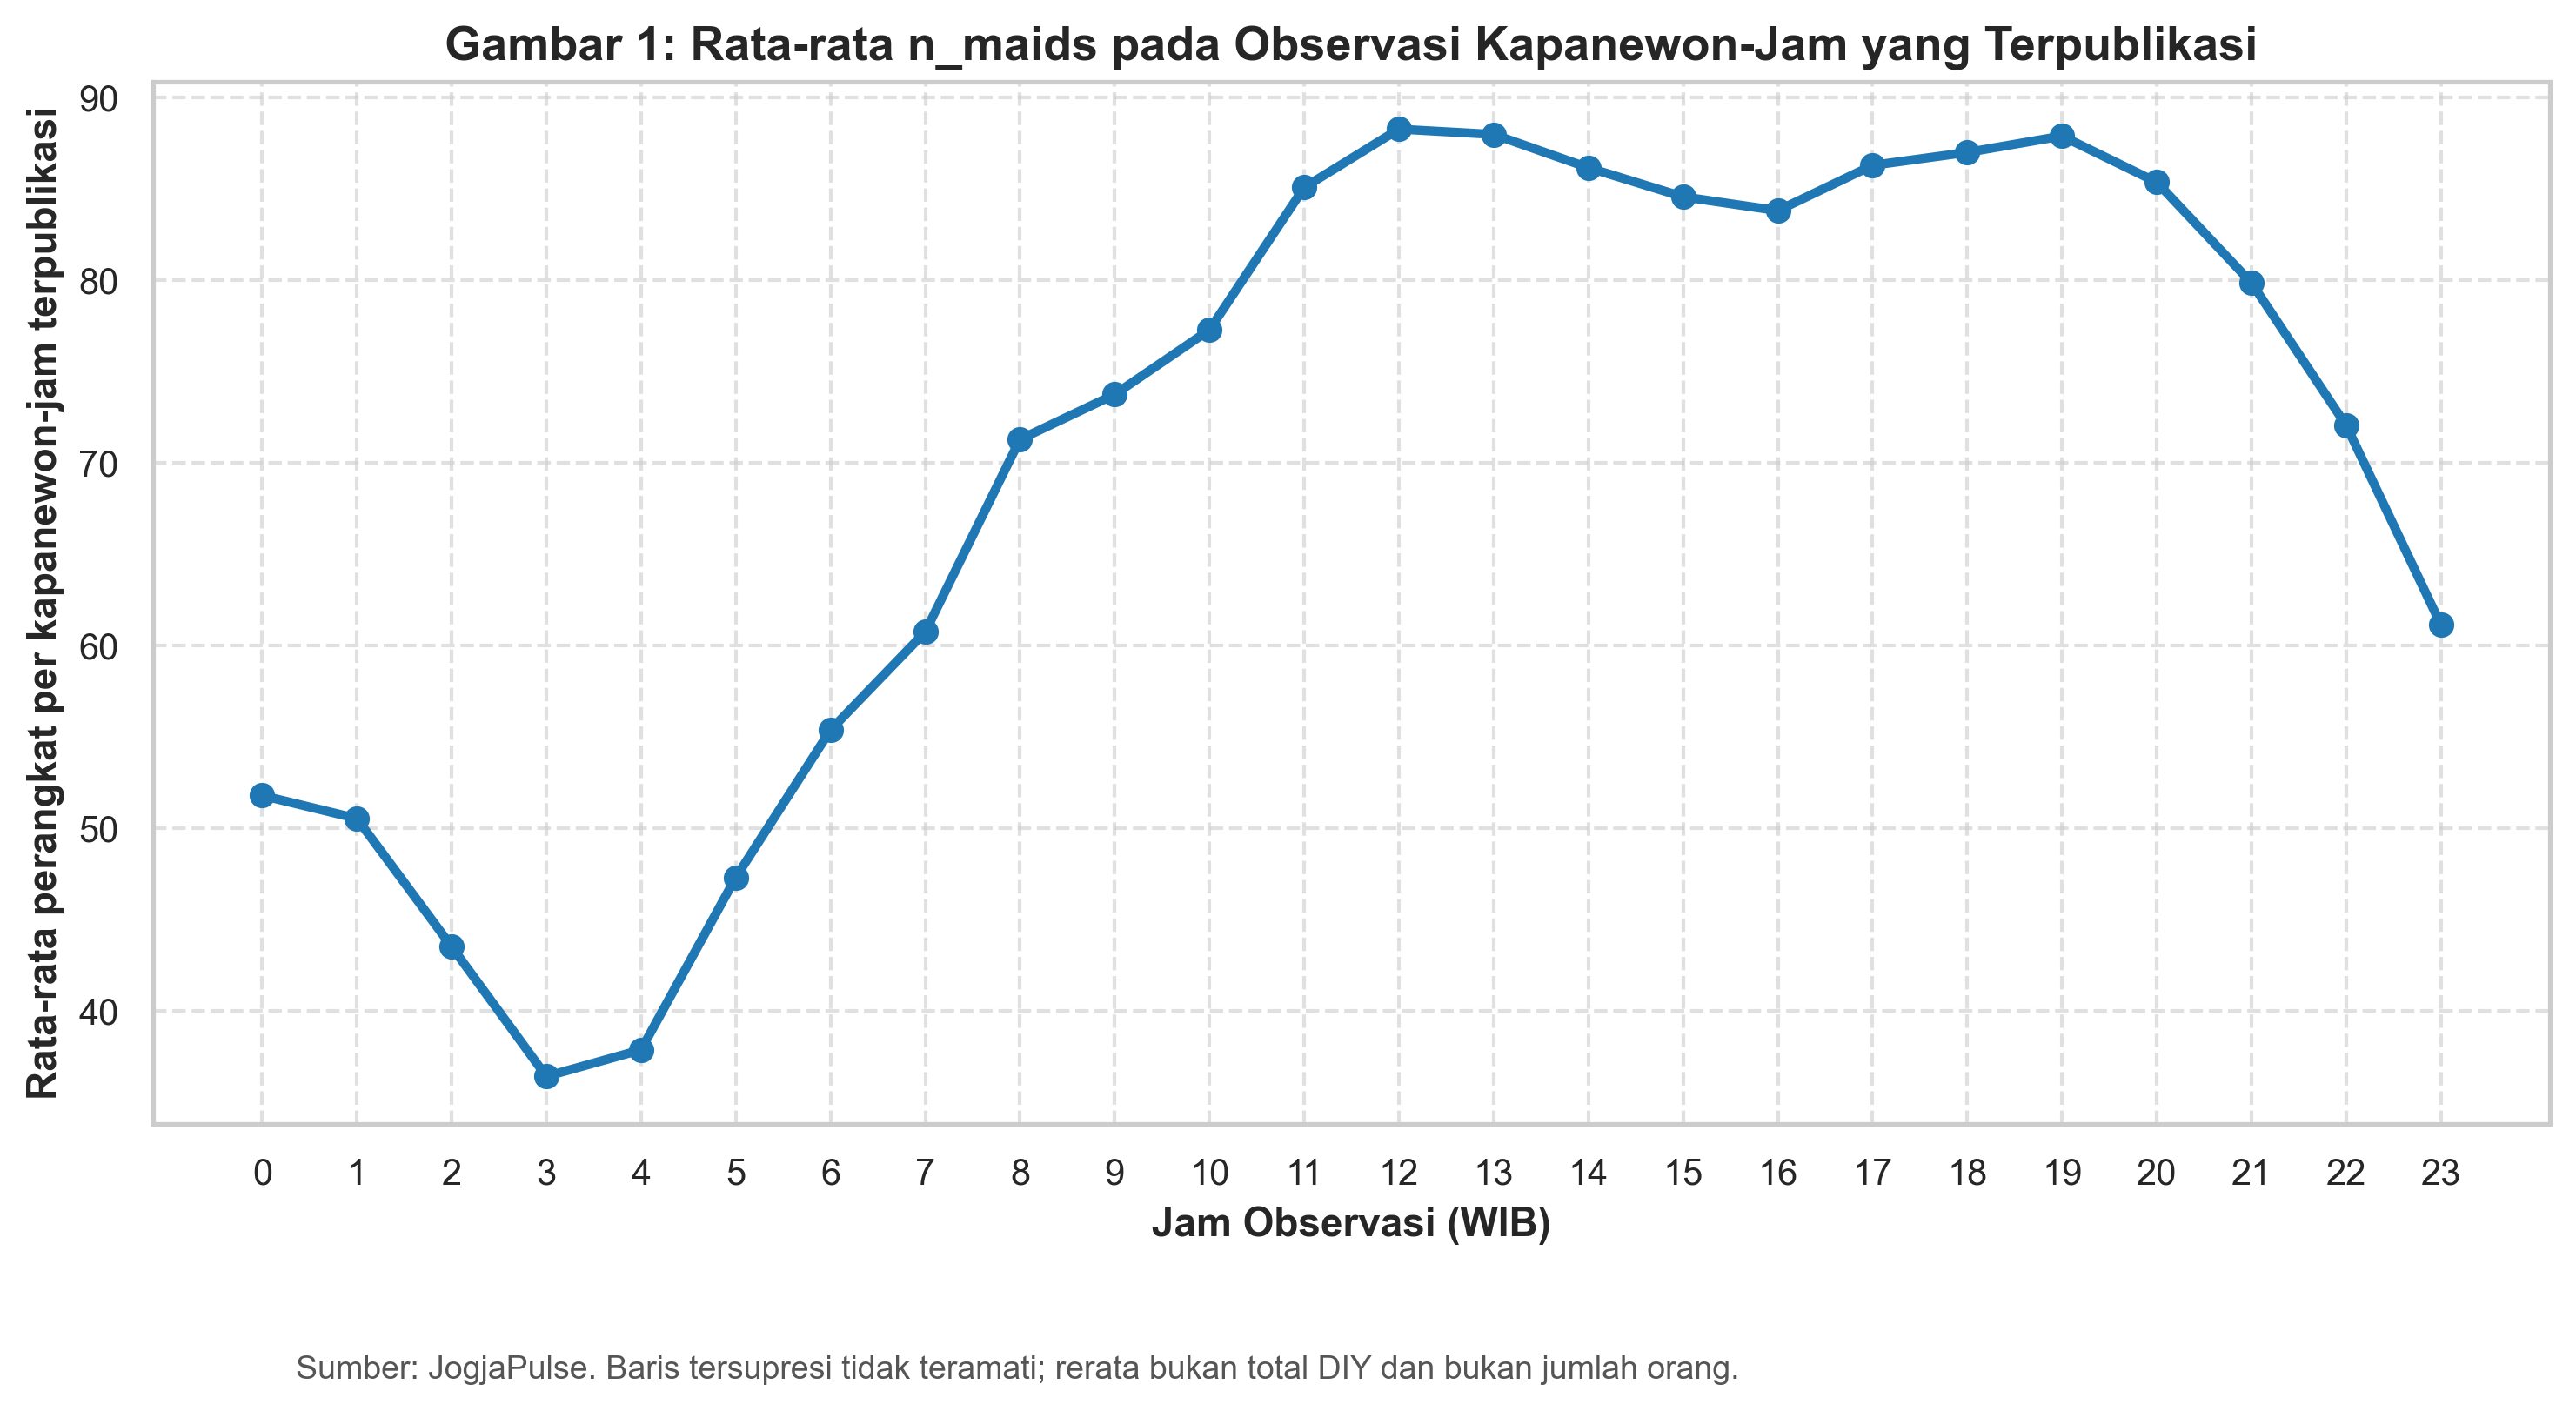

In [18]:
# 5.1 Profil 24 jam: rerata n_maids pada baris kapanewon-jam yang dipublikasikan
# Ini rerata lintas observasi yang tersedia, bukan total perangkat DIY.
hourly_profile = df_pres_kapanewon.groupby("hour")["n_maids"].agg(["mean", "count"]).reset_index()
hourly_profile = hourly_profile.rename(columns={"mean": "mean_n_maids_published", "count": "published_kapanewon_hour_rows"})

plt.figure(figsize=(10, 5))
plt.plot(hourly_profile["hour"], hourly_profile["mean_n_maids_published"], marker="o", color="#1f77b4", linewidth=2.5)
plt.title("Gambar 1: Rata-rata n_maids pada Observasi Kapanewon-Jam yang Terpublikasi")
plt.xlabel("Jam Observasi (WIB)")
plt.ylabel("Rata-rata perangkat per kapanewon-jam terpublikasi")
plt.xticks(range(24))
plt.grid(True, linestyle="--", alpha=0.6)
plt.figtext(0.12, -0.07, "Sumber: JogjaPulse. Baris tersupresi tidak teramati; rerata bukan total DIY dan bukan jumlah orang.", fontsize=9, color="#555555")
plt.savefig(FIGURES_DIR / "01_profil_kehadiran_24jam_diy.png", bbox_inches="tight")
plt.show()
hourly_profile.to_csv(TABLES_DIR / "rq1_profil_jam_diy.csv", index=False)


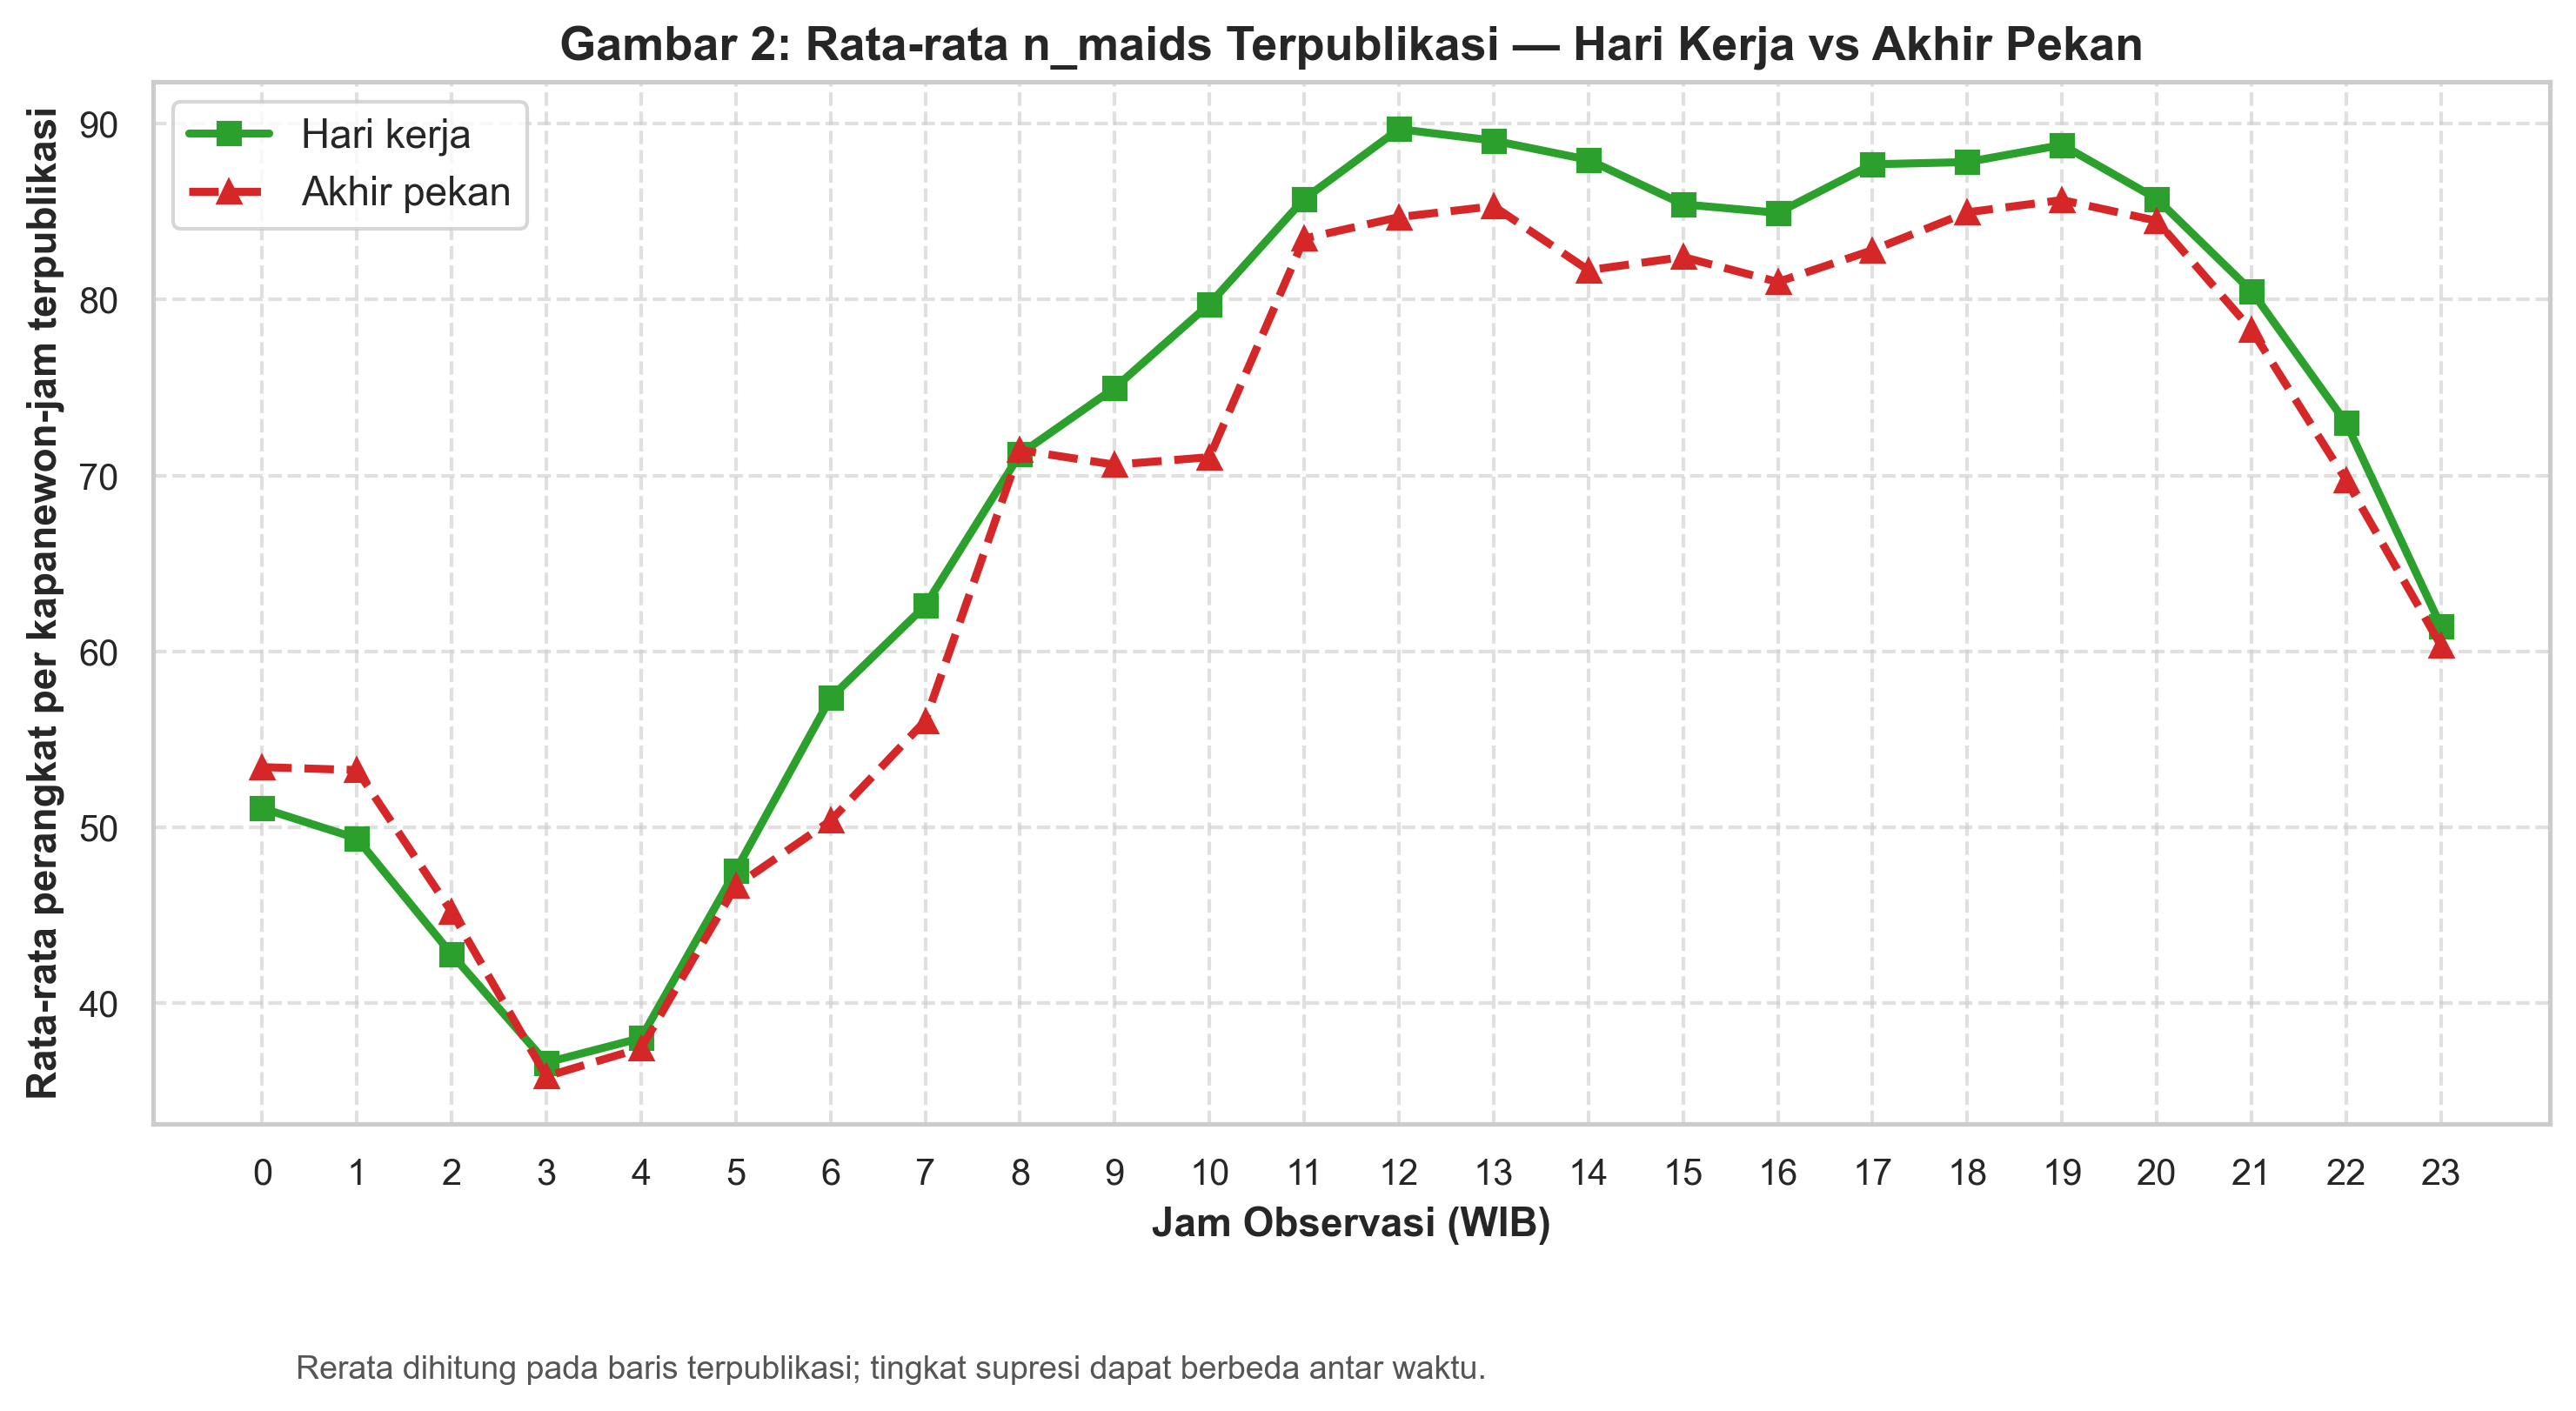

In [19]:
# 5.2 Profil jam weekday vs weekend; rerata hanya atas baris terpublikasi
df_pres_kapanewon["is_weekend"] = df_pres_kapanewon["date"].dt.dayofweek.isin([5, 6])
profile_ww = df_pres_kapanewon.groupby(["hour", "is_weekend"])["n_maids"].mean().unstack().reset_index()
profile_ww.columns = ["hour", "Hari Kerja (Senin-Jumat)", "Akhir Pekan (Sabtu-Minggu)"]
plt.figure(figsize=(10, 5))
plt.plot(profile_ww["hour"], profile_ww["Hari Kerja (Senin-Jumat)"], marker="s", label="Hari kerja", color="#2ca02c", linewidth=2.2)
plt.plot(profile_ww["hour"], profile_ww["Akhir Pekan (Sabtu-Minggu)"], marker="^", label="Akhir pekan", color="#d62728", linewidth=2.2, linestyle="--")
plt.title("Gambar 2: Rata-rata n_maids Terpublikasi — Hari Kerja vs Akhir Pekan")
plt.xlabel("Jam Observasi (WIB)"); plt.ylabel("Rata-rata perangkat per kapanewon-jam terpublikasi")
plt.xticks(range(24)); plt.legend(); plt.grid(True, linestyle="--", alpha=0.6)
plt.figtext(0.12, -0.07, "Rerata dihitung pada baris terpublikasi; tingkat supresi dapat berbeda antar waktu.", fontsize=9, color="#555555")
plt.savefig(FIGURES_DIR / "02_pola_weekday_vs_weekend.png", bbox_inches="tight")
plt.show()
profile_ww.to_csv(TABLES_DIR / "rq1_profil_weekday_vs_weekend.csv", index=False)


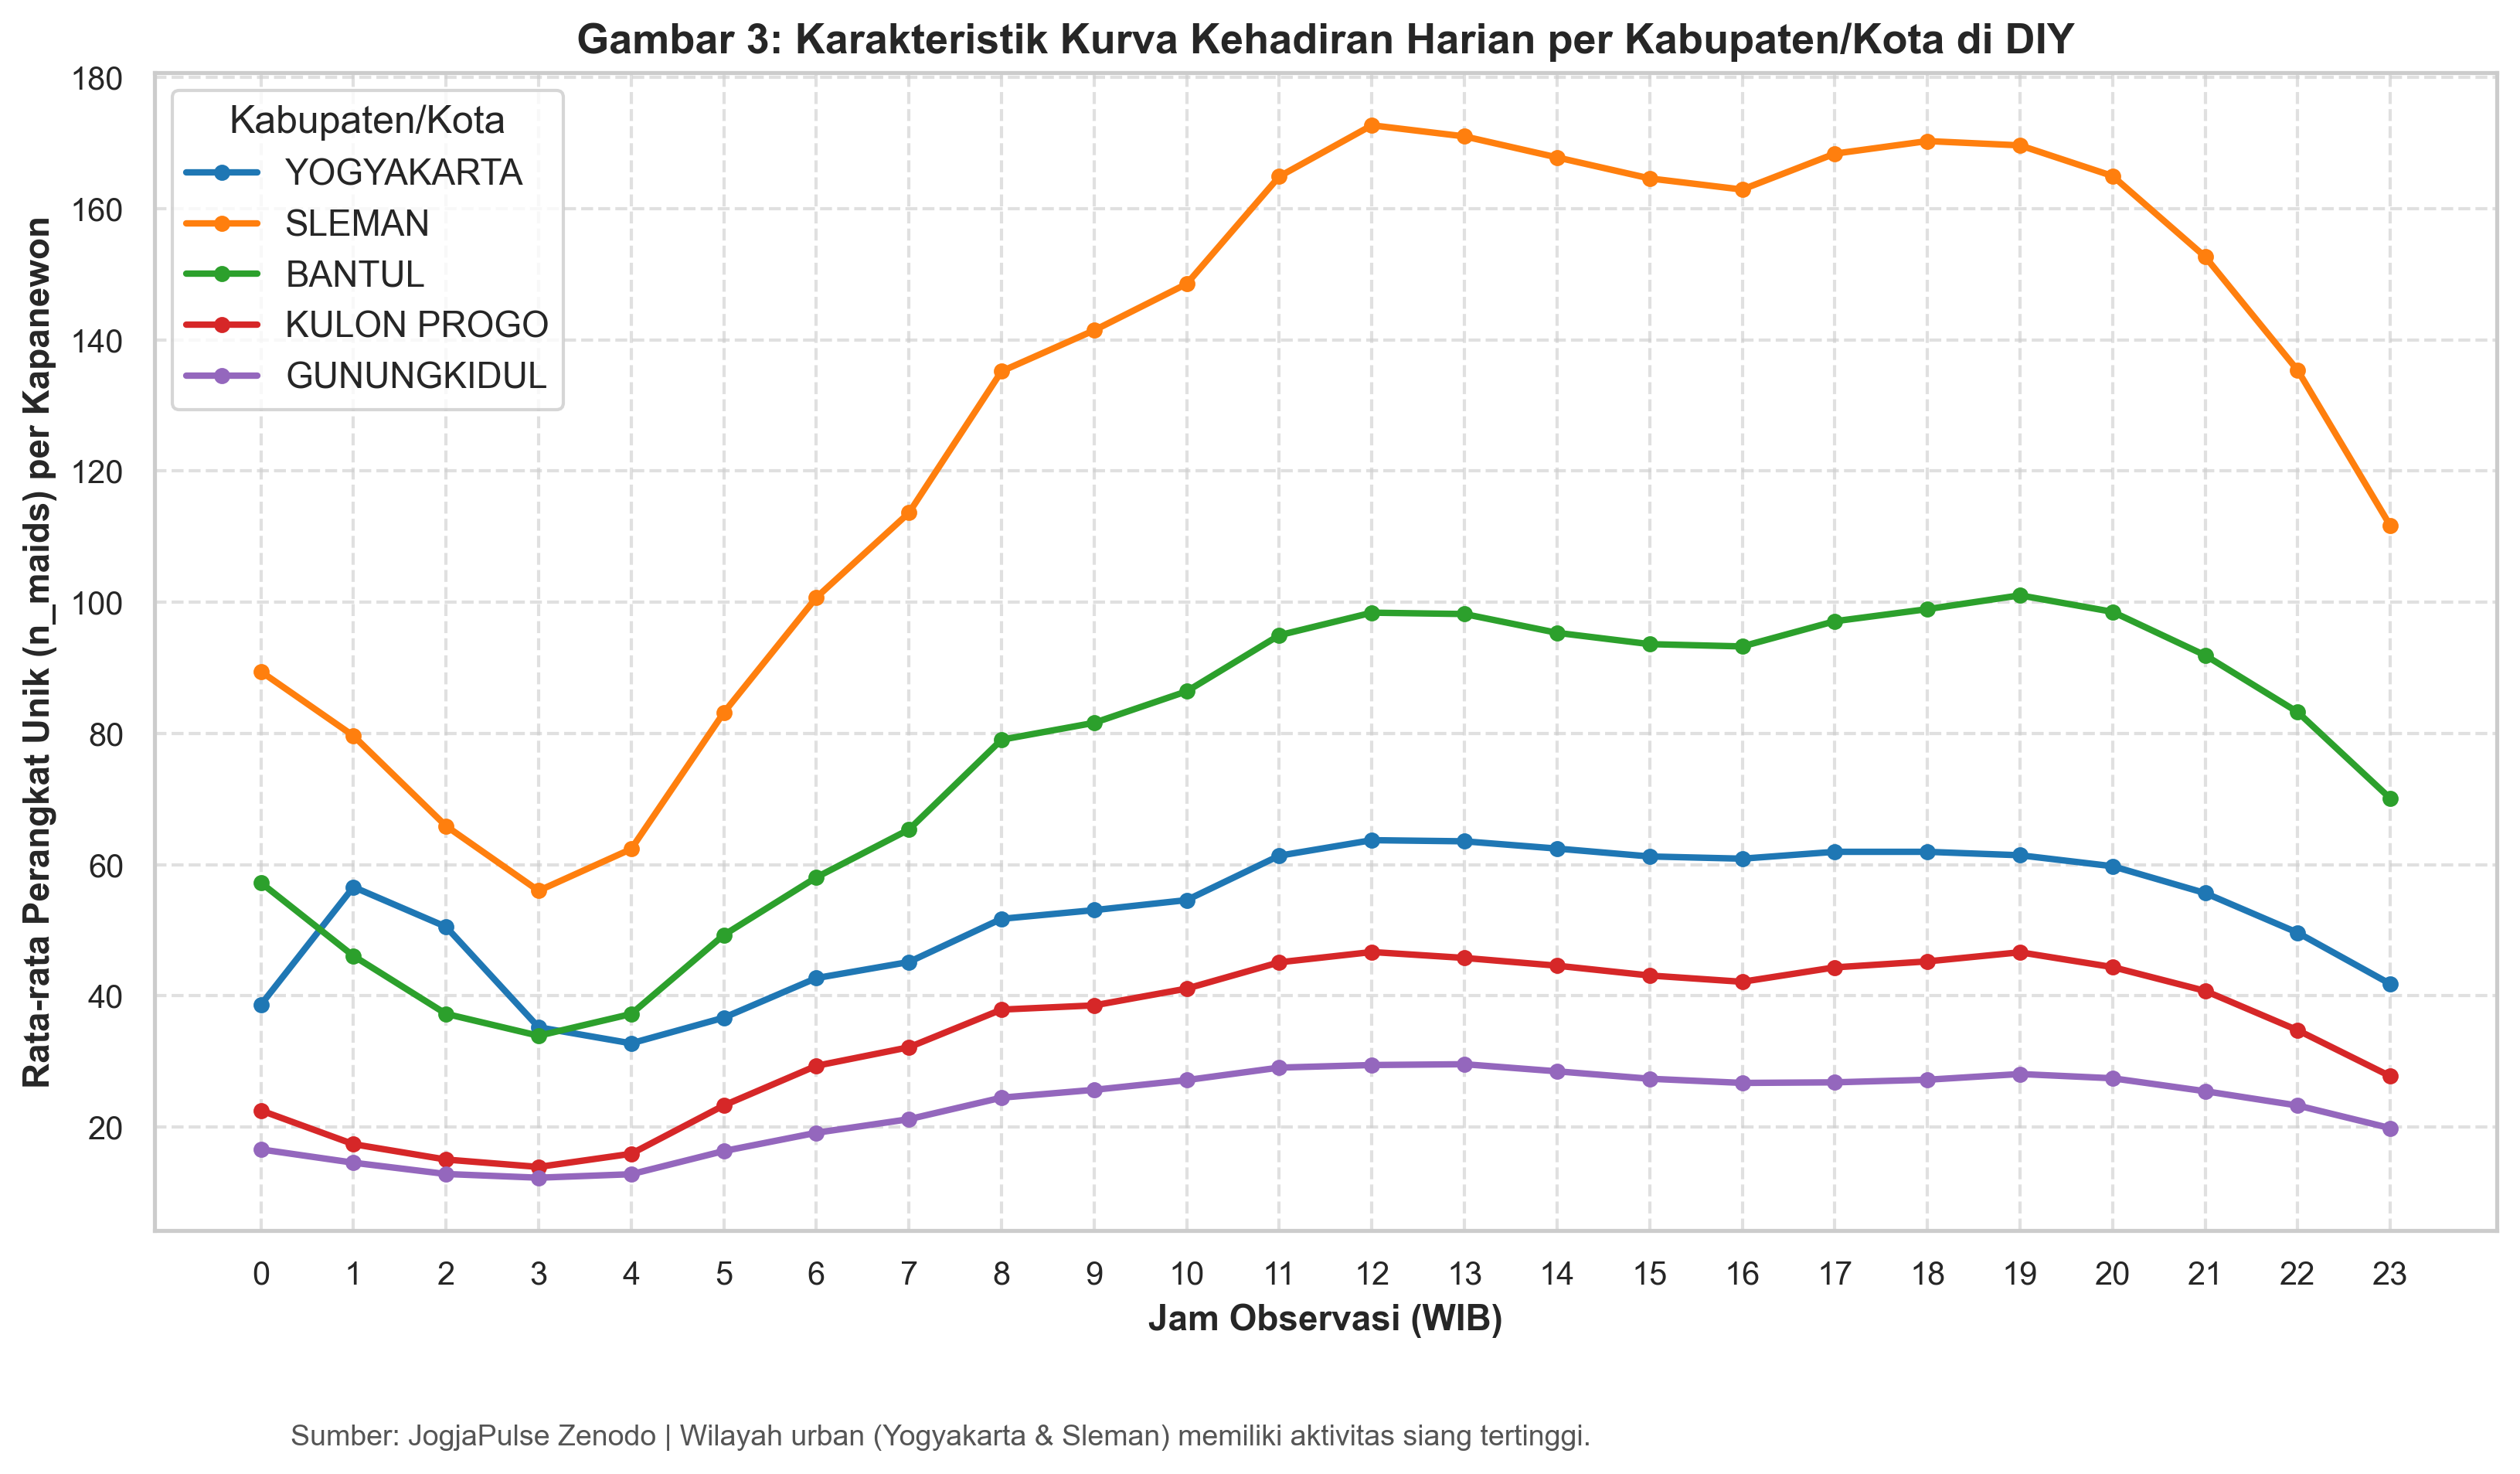

In [20]:
# 5.3 Perhitungan & Visualisasi Gambar 3: Profil Kehadiran per 5 Kabupaten/Kota
kab_profile = df_pres_kapanewon.groupby(["hour", "kab_kota"])["n_maids"].mean().unstack().reset_index()

plt.figure(figsize=(11, 6))
for kab in ["YOGYAKARTA", "SLEMAN", "BANTUL", "KULON PROGO", "GUNUNGKIDUL"]:
    plt.plot(kab_profile["hour"], kab_profile[kab], marker="o", markersize=4, label=kab, linewidth=2)

plt.title("Gambar 3: Karakteristik Kurva Kehadiran Harian per Kabupaten/Kota di DIY")
plt.xlabel("Jam Observasi (WIB)")
plt.ylabel("Rata-rata Perangkat Unik (n_maids) per Kapanewon")
plt.xticks(range(0, 24))
plt.legend(title="Kabupaten/Kota", frameon=True)
plt.grid(True, linestyle="--", alpha=0.6)
plt.figtext(0.12, -0.05, "Sumber: JogjaPulse Zenodo | Wilayah urban (Yogyakarta & Sleman) memiliki aktivitas siang tertinggi.", fontsize=9, color="#555555")
plt.savefig(os.path.join(FIGURES_DIR, "03_profil_kehadiran_per_kabupaten.png"), bbox_inches="tight")
plt.show()

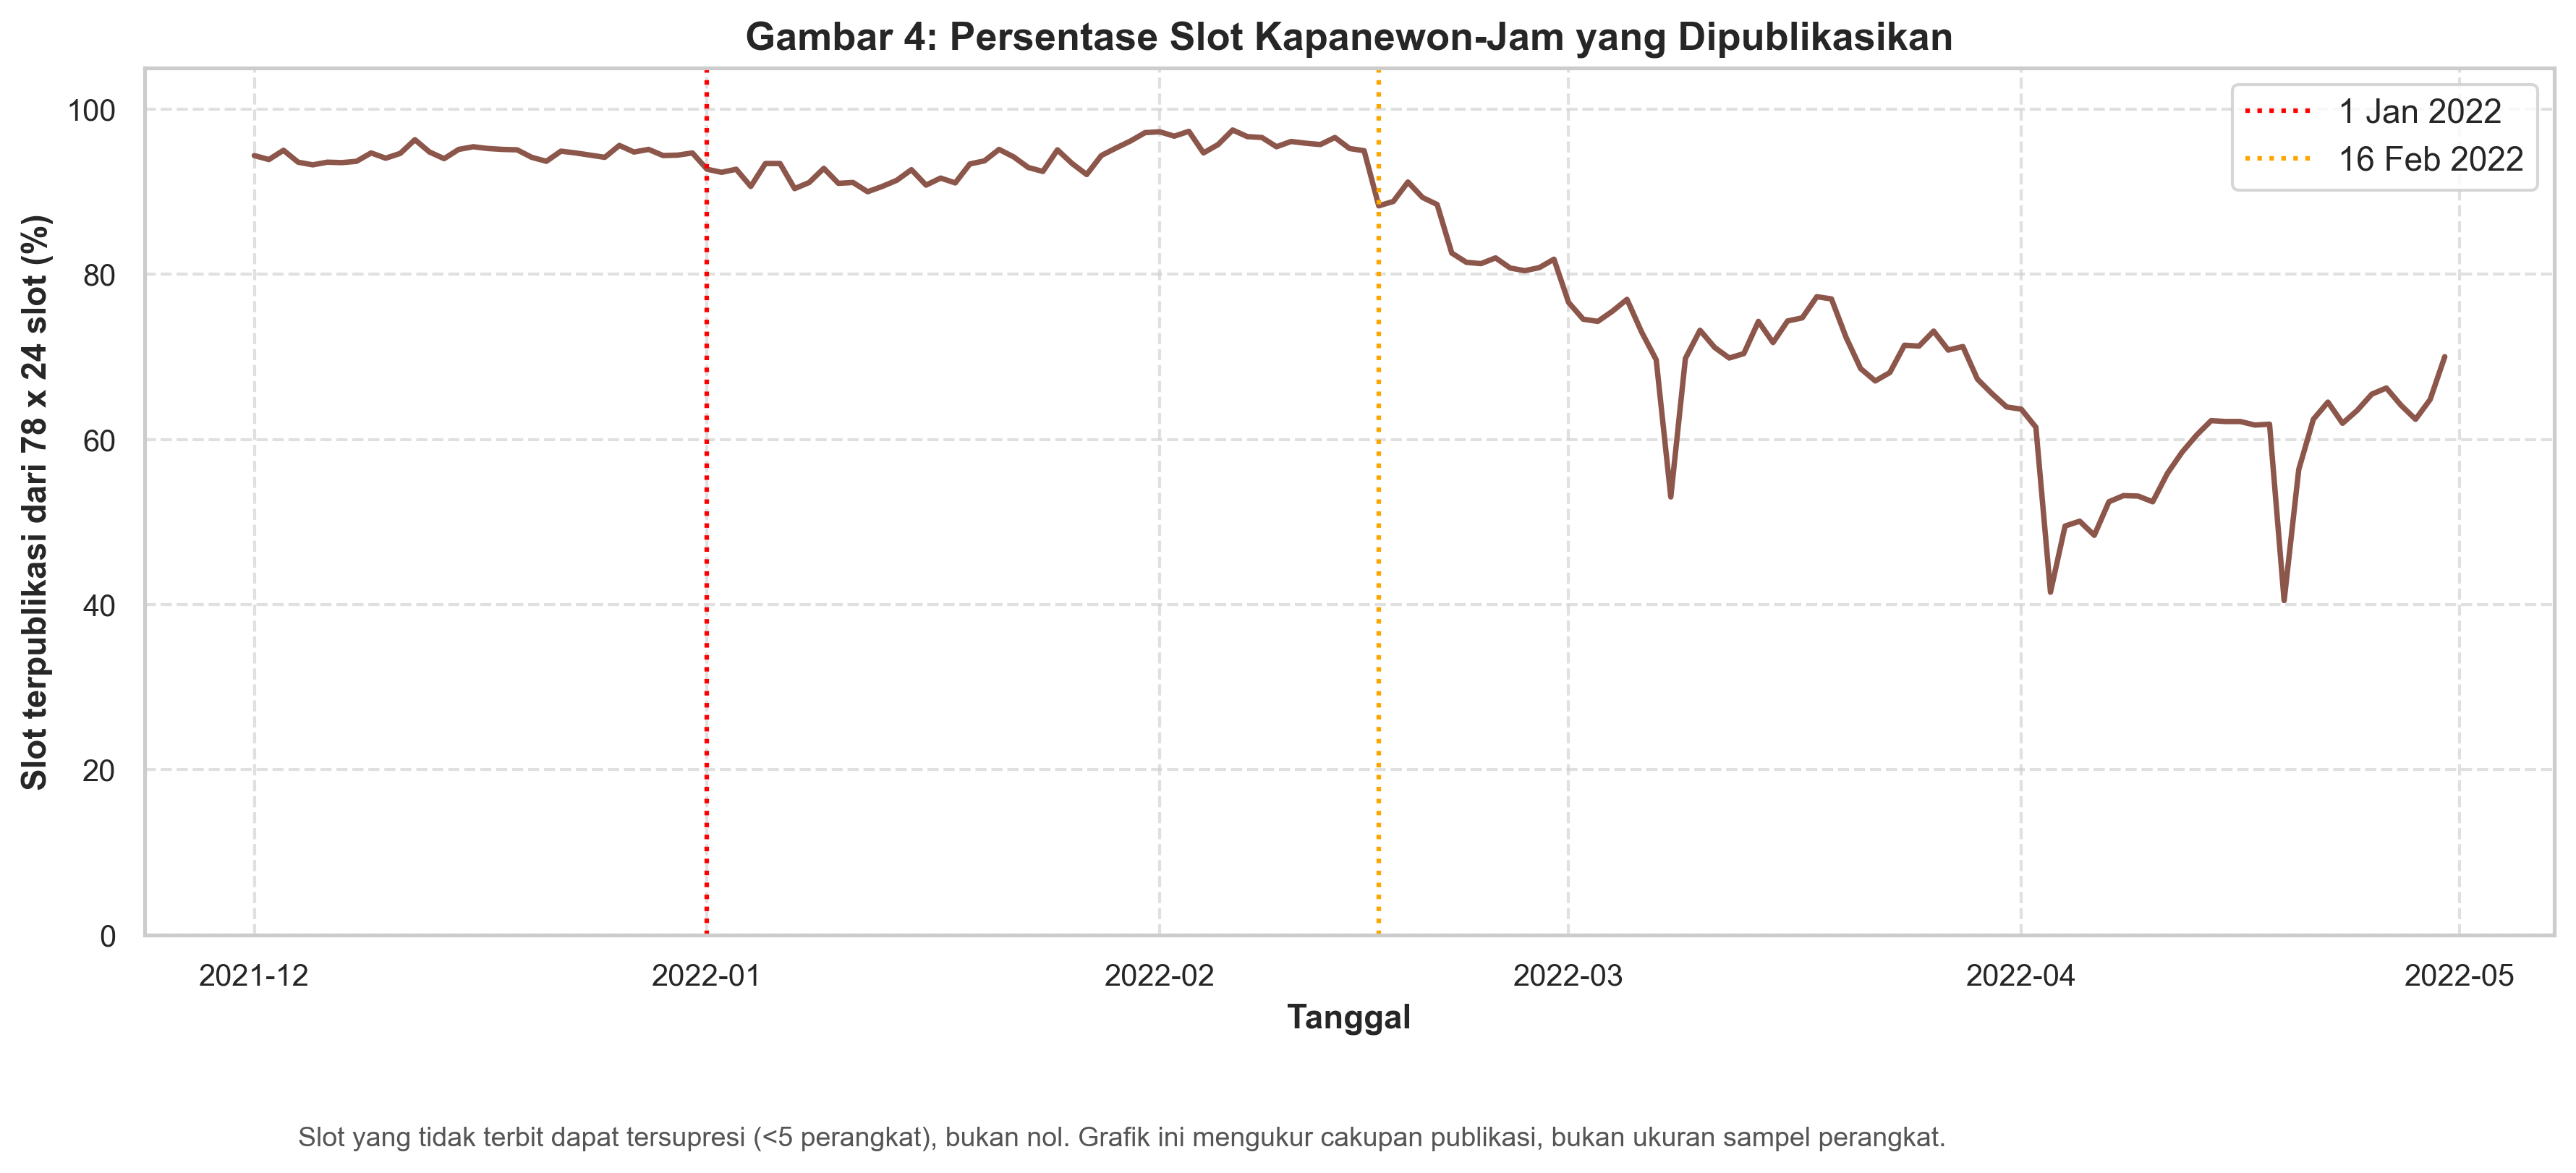

In [21]:
# 5.4 Tren cakupan observasi harian, bukan jumlah total perangkat
# Setiap tanggal idealnya memiliki 78 kapanewon x 24 jam slot.
expected_slots = 78 * 24
daily_coverage = (df_pres_kapanewon.groupby("date").size().rename("published_slots").reset_index())
daily_coverage["expected_slots"] = expected_slots
daily_coverage["published_slot_pct"] = 100 * daily_coverage["published_slots"] / expected_slots

plt.figure(figsize=(12, 5))
plt.plot(daily_coverage["date"], daily_coverage["published_slot_pct"], color="#8c564b", linewidth=1.8)
plt.axvline(pd.Timestamp("2022-01-01"), color="red", linestyle=":", label="1 Jan 2022")
plt.axvline(pd.Timestamp("2022-02-16"), color="orange", linestyle=":", label="16 Feb 2022")
plt.title("Gambar 4: Persentase Slot Kapanewon-Jam yang Dipublikasikan")
plt.xlabel("Tanggal"); plt.ylabel("Slot terpublikasi dari 78 x 24 slot (%)")
plt.ylim(0, 105); plt.legend(); plt.grid(True, linestyle="--", alpha=0.6)
plt.figtext(0.12, -0.07, "Slot yang tidak terbit dapat tersupresi (<5 perangkat), bukan nol. Grafik ini mengukur cakupan publikasi, bukan ukuran sampel perangkat.", fontsize=9, color="#555555")
plt.savefig(FIGURES_DIR / "04_tren_penurunan_sampel_harian.png", bbox_inches="tight")
plt.show()
daily_coverage.to_csv(TABLES_DIR / "rq1_cakupan_slot_harian.csv", index=False)


### 5.5 Pembahasan RQ1
Baca kurva sebagai rata-rata pada observasi kapanewon-jam yang diterbitkan. Karena nilai kecil disupresi dan cakupan publikasi berubah, pola ini mendeskripsikan data yang tersedia, bukan keseluruhan penduduk atau jumlah total perangkat DIY. Untuk perbandingan waktu, perhatikan grafik cakupan slot terpublikasi dan hindari menyimpulkan perubahan mobilitas populasi dari hitungan mentah.


<a name="sec-6"></a>
## 6. Analisis RQ2: Arus Kunjungan Asal-Tujuan (OD Flows)

**Pertanyaan Riset 2 (RQ2):**
> *Kapanewon mana yang menjadi tujuan kunjungan lintas-kapanewon terbesar pada Desember 2021 – Februari 2022?*

Sesuai panduan rekayasa data:
* Mengisolasi data pada periode kualitas tinggi (**Desember 2021 – Februari 2022**, `reduced_quality == False`).
* Mengecualikan pergerakan *intrazonal* ($origin == dest$) agar murni menganalisis arus lintas-wilayah (*inter-zonal flows*).
* Menghitung akumulasi pengunjung bulanan (*monthly visitors*).

In [22]:
# 6.1 Persiapan Data Bersih OD Inter-zonal (Desember 2021 - Februari 2022)
od_clean = df_od_visits[
    (~df_od_visits["reduced_quality"]) & 
    (df_od_visits["origin_code"] != df_od_visits["dest_code"])
].copy()

print(f"Total baris arus inter-zonal kualitas tinggi (Des 2021 - Feb 2022): {len(od_clean):,} baris")

Total baris arus inter-zonal kualitas tinggi (Des 2021 - Feb 2022): 7,638 baris


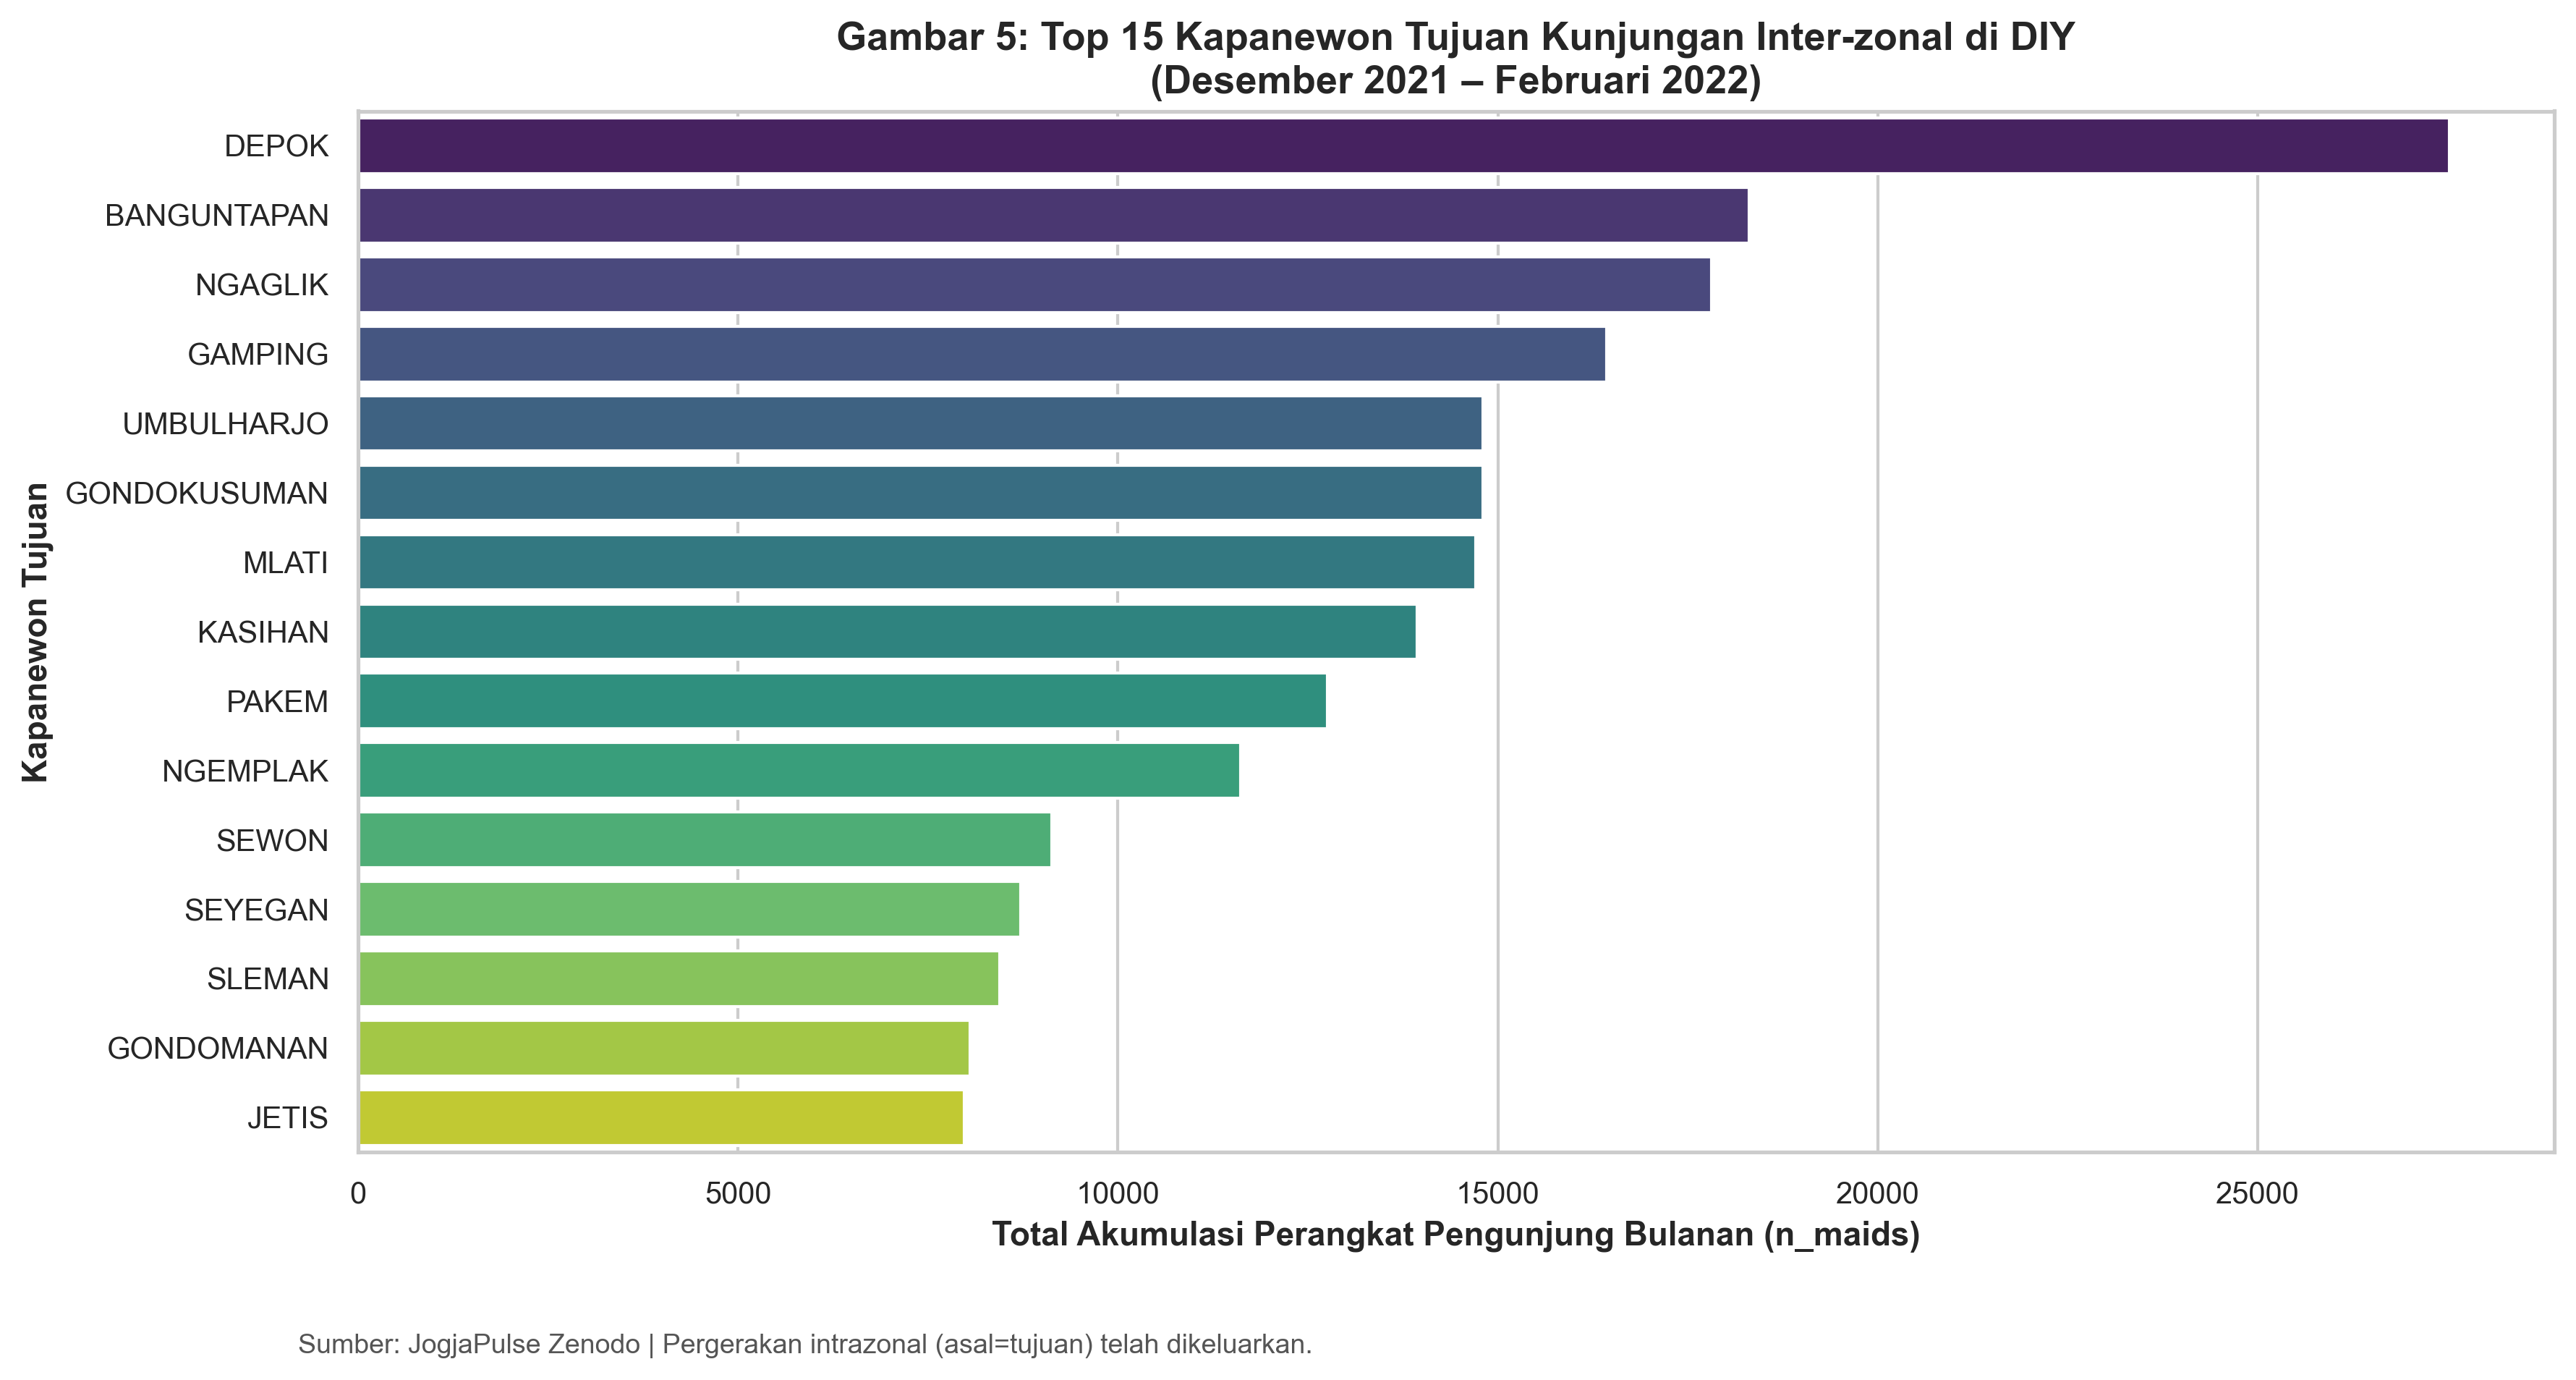

,Kabupaten/Kota,Kapanewon Tujuan,Total Pengunjung (n_maids)
0,SLEMAN,DEPOK,27529
1,BANTUL,BANGUNTAPAN,18306
2,SLEMAN,NGAGLIK,17813
3,SLEMAN,GAMPING,16437
4,YOGYAKARTA,UMBULHARJO,14807
5,YOGYAKARTA,GONDOKUSUMAN,14801
6,SLEMAN,MLATI,14707
7,BANTUL,KASIHAN,13939
8,SLEMAN,PAKEM,12762
9,SLEMAN,NGEMPLAK,11612


In [23]:
# 6.2 Perhitungan & Visualisasi Gambar 5: Top 15 Kapanewon Tujuan Inter-zonal
top15_dest = od_clean.groupby(["dest_kab_kota", "dest_kapanewon"])["n_maids"].sum().reset_index()
top15_dest = top15_dest.sort_values("n_maids", ascending=False).head(15).reset_index(drop=True)
top15_dest.columns = ["Kabupaten/Kota", "Kapanewon Tujuan", "Total Pengunjung (n_maids)"]

plt.figure(figsize=(12, 6))
sns.barplot(data=top15_dest, x="Total Pengunjung (n_maids)", y="Kapanewon Tujuan", palette="viridis")
plt.title("Gambar 5: Top 15 Kapanewon Tujuan Kunjungan Inter-zonal di DIY\n(Desember 2021 – Februari 2022)")
plt.xlabel("Total Akumulasi Perangkat Pengunjung Bulanan (n_maids)")
plt.ylabel("Kapanewon Tujuan")
plt.figtext(0.12, -0.05, "Sumber: JogjaPulse Zenodo | Pergerakan intrazonal (asal=tujuan) telah dikeluarkan.", fontsize=9, color="#555555")
plt.savefig(os.path.join(FIGURES_DIR, "05_top15_kapanewon_tujuan_interzonal.png"), bbox_inches="tight")
plt.show()

display(top15_dest)
top15_dest.to_csv(os.path.join(TABLES_DIR, "rq2_top15_destinasi_interzonal.csv"), index=False)

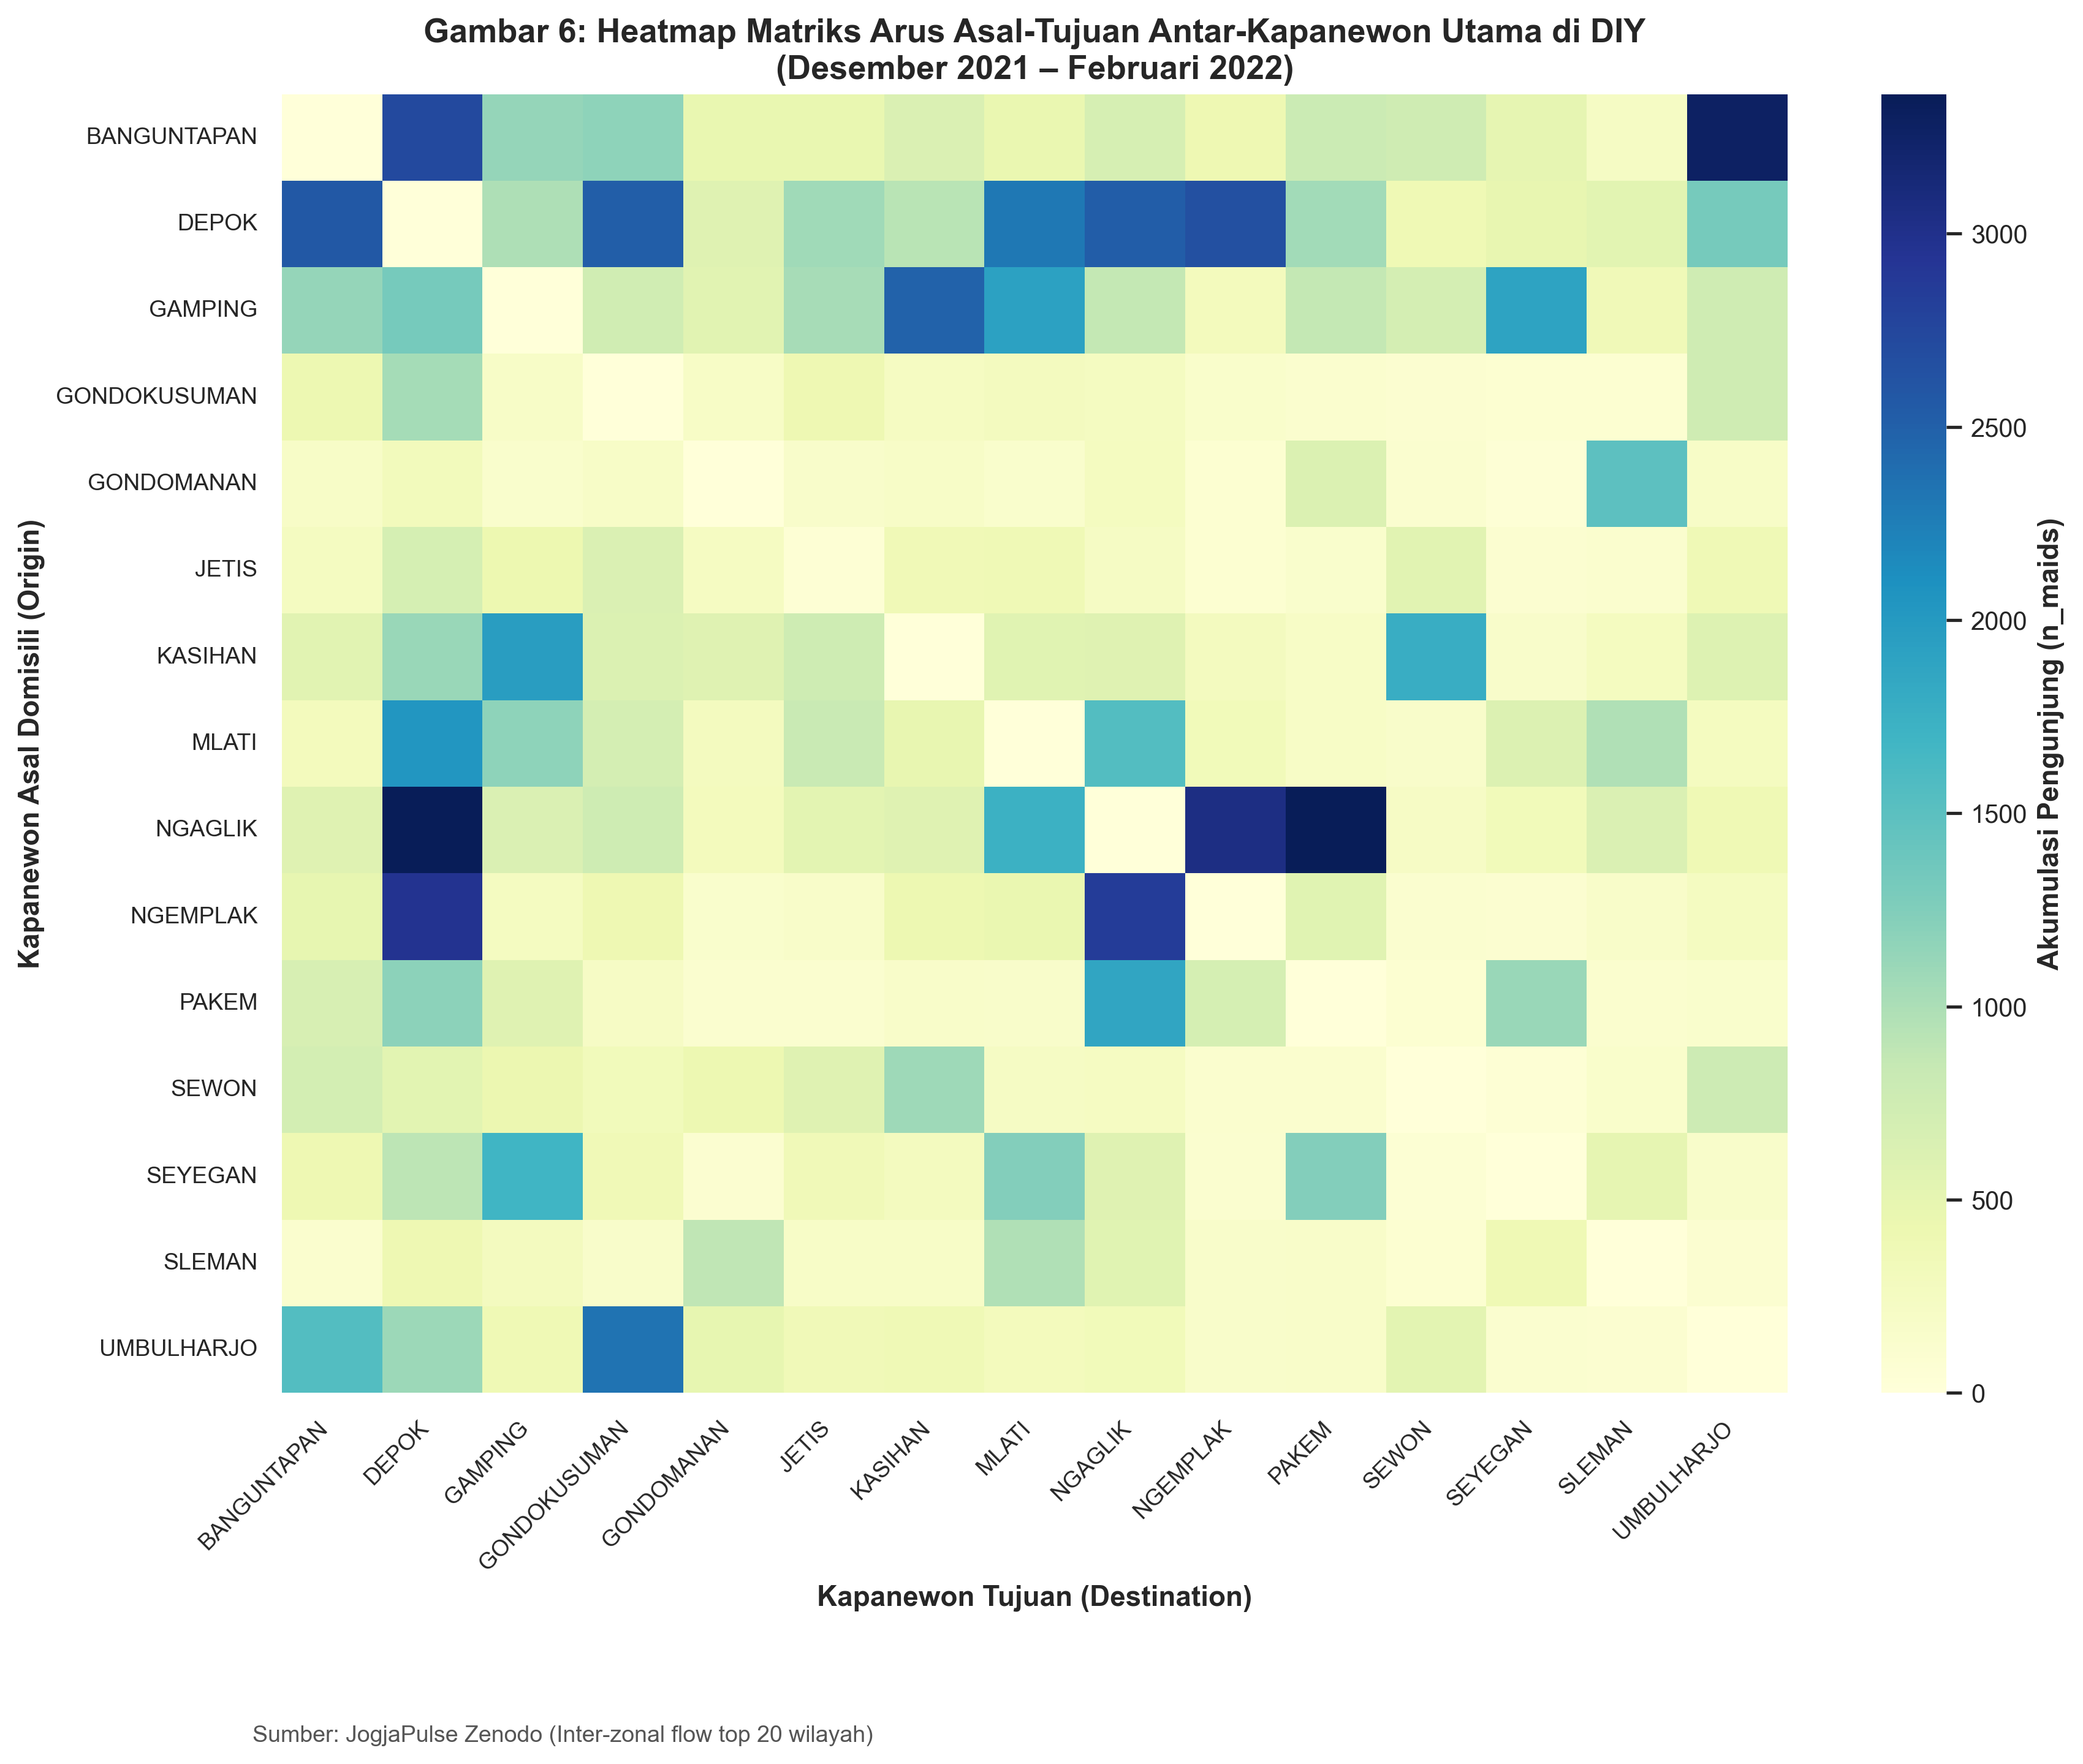

In [24]:
# 6.3 Visualisasi Gambar 6: Heatmap Interaksi Asal-Tujuan Top 20 Kapanewon
top20_names = top15_dest["Kapanewon Tujuan"].head(20).tolist()
od_top20 = od_clean[
    (od_clean["origin_kapanewon"].isin(top20_names)) & 
    (od_clean["dest_kapanewon"].isin(top20_names))
]
pivot_top20 = od_top20.pivot_table(index="origin_kapanewon", columns="dest_kapanewon", values="n_maids", aggfunc="sum", fill_value=0)

plt.figure(figsize=(12, 9))
sns.heatmap(pivot_top20, cmap="YlGnBu", annot=False, cbar_kws={'label': 'Akumulasi Pengunjung (n_maids)'})
plt.title("Gambar 6: Heatmap Matriks Arus Asal-Tujuan Antar-Kapanewon Utama di DIY\n(Desember 2021 – Februari 2022)")
plt.xlabel("Kapanewon Tujuan (Destination)")
plt.ylabel("Kapanewon Asal Domisili (Origin)")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(fontsize=9)
plt.figtext(0.12, -0.06, "Sumber: JogjaPulse Zenodo (Inter-zonal flow top 20 wilayah)", fontsize=9, color="#555555")
plt.savefig(os.path.join(FIGURES_DIR, "06_heatmap_matriks_od_top20.png"), bbox_inches="tight")
plt.show()

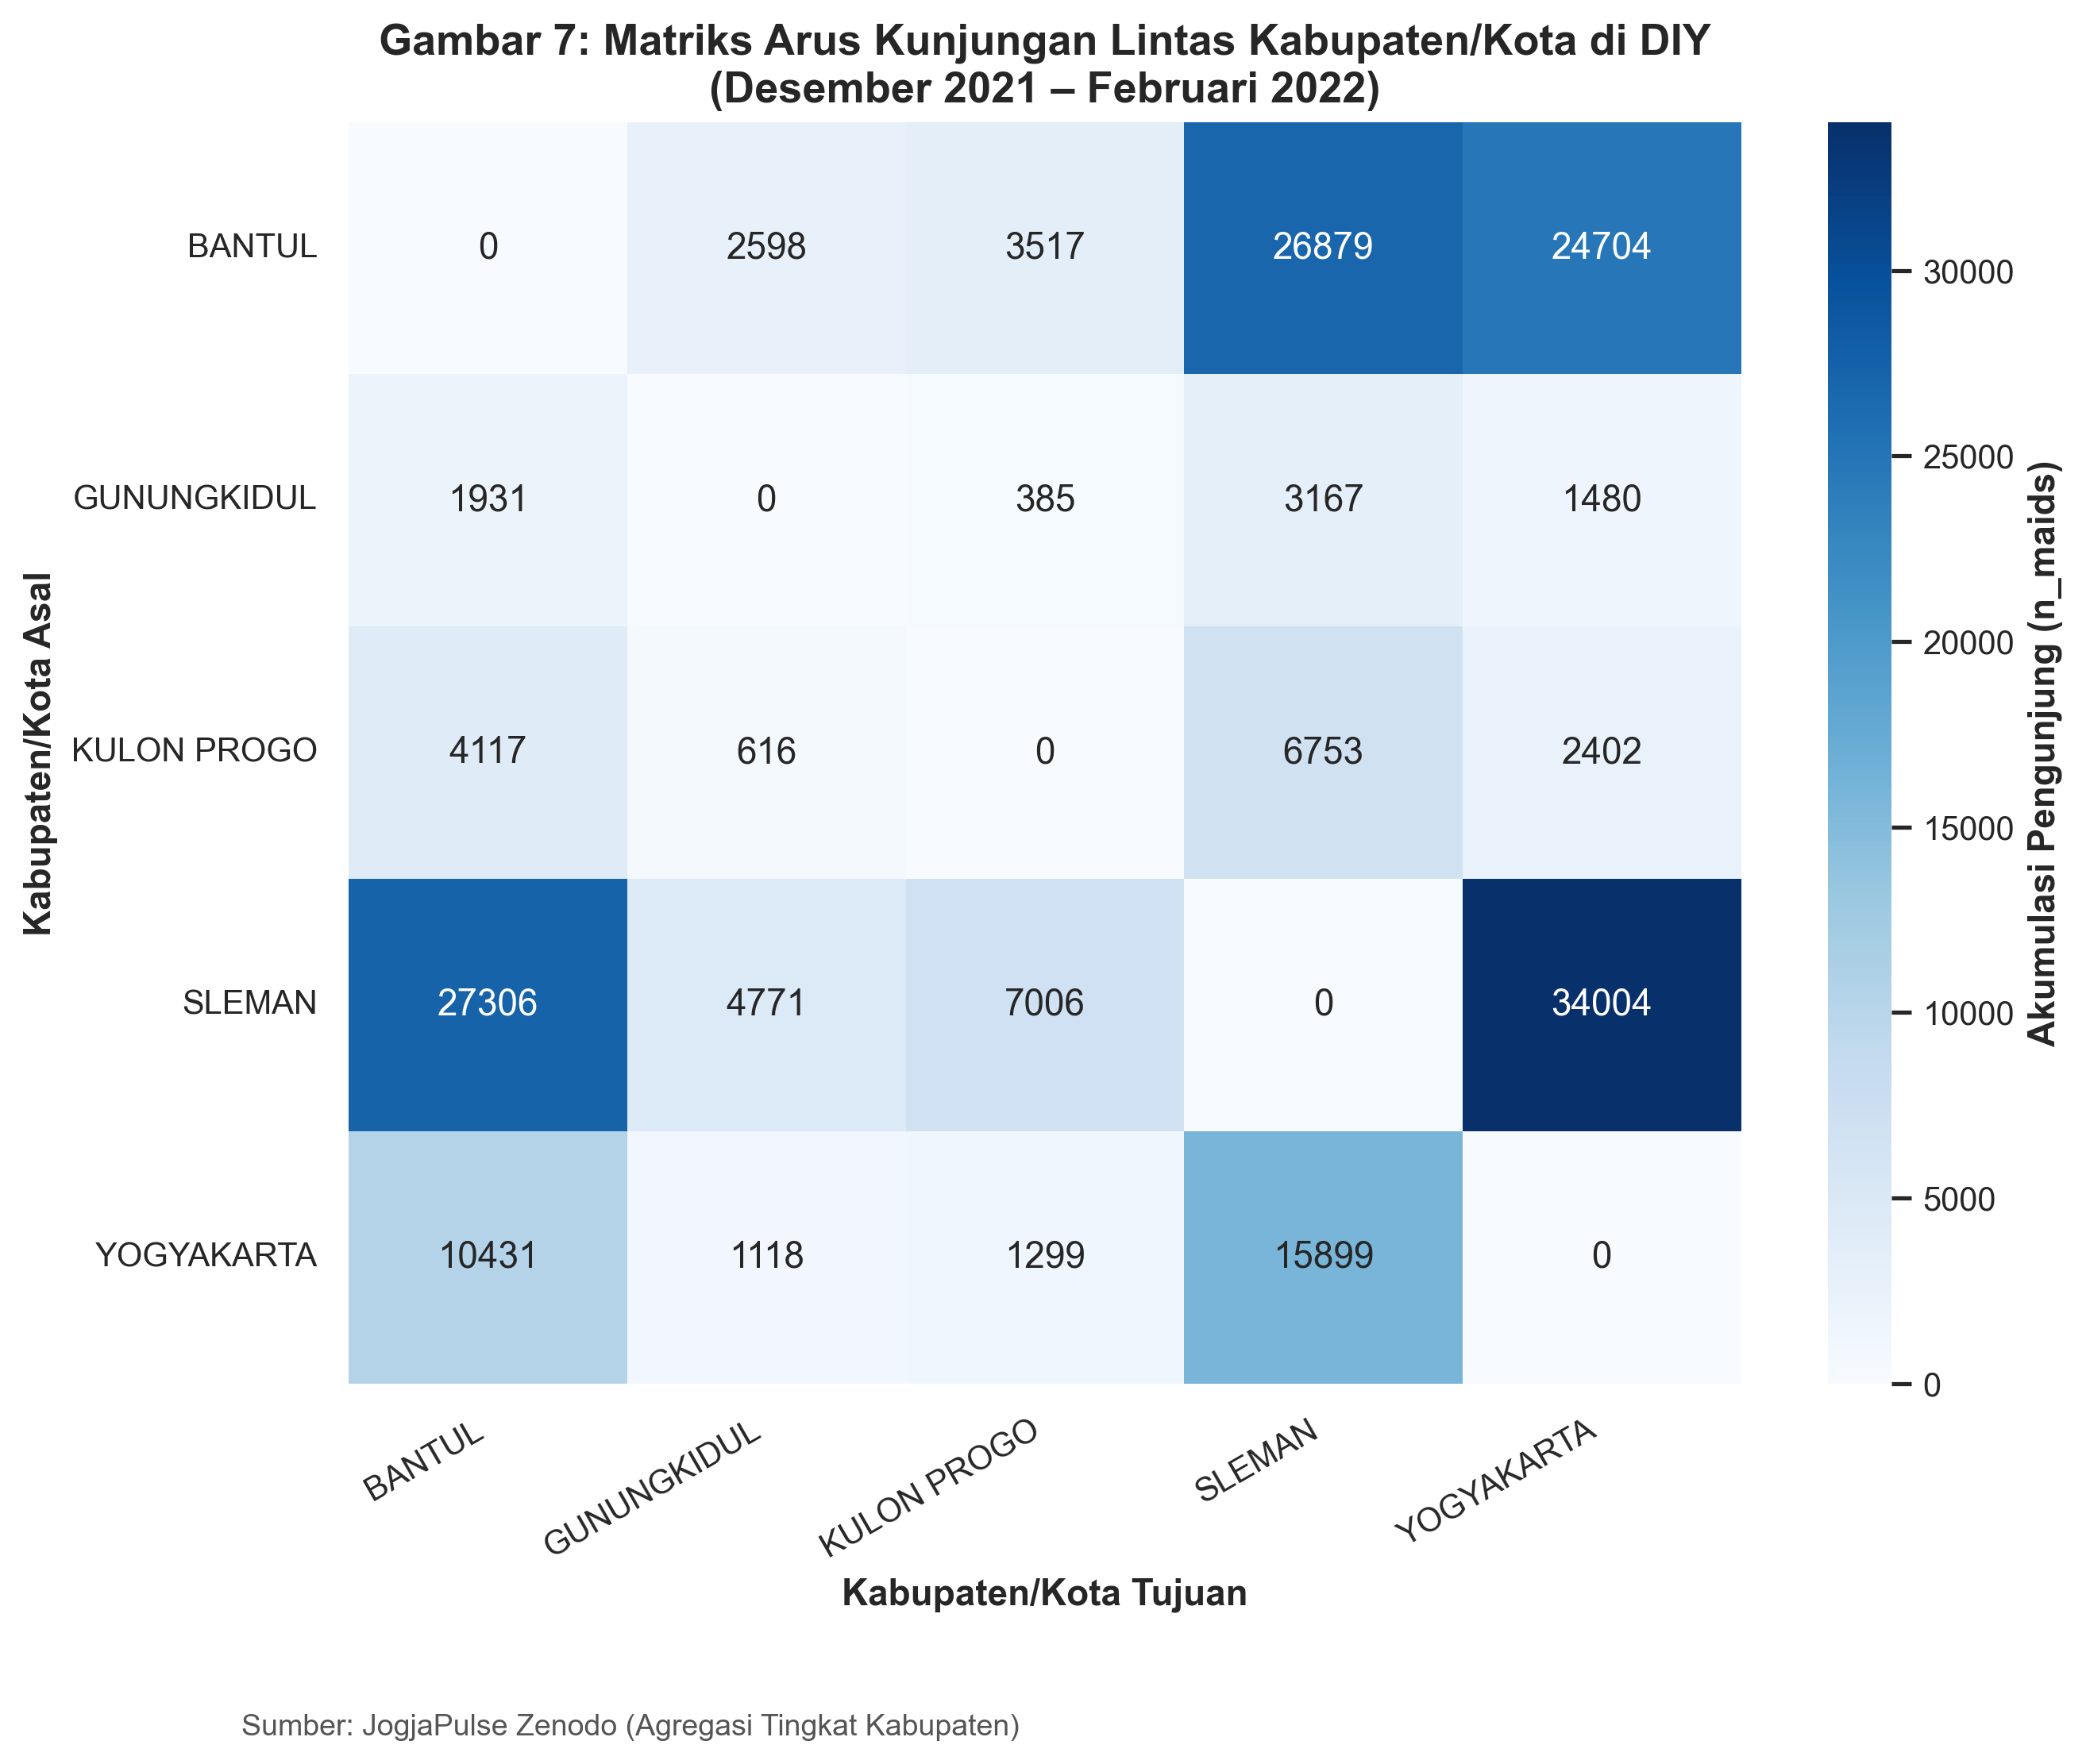

In [25]:
# 6.4 Visualisasi Gambar 7: Matriks Arus Lintas Kabupaten/Kota
plt.figure(figsize=(9, 7))
sns.heatmap(pivot_kab, annot=True, fmt="d", cmap="Blues", cbar_kws={'label': 'Akumulasi Pengunjung (n_maids)'})
plt.title("Gambar 7: Matriks Arus Kunjungan Lintas Kabupaten/Kota di DIY\n(Desember 2021 – Februari 2022)")
plt.xlabel("Kabupaten/Kota Tujuan")
plt.ylabel("Kabupaten/Kota Asal")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.figtext(0.12, -0.05, "Sumber: JogjaPulse Zenodo (Agregasi Tingkat Kabupaten)", fontsize=9, color="#555555")
plt.savefig(os.path.join(FIGURES_DIR, "07_arus_od_antar_kabupaten.png"), bbox_inches="tight")
plt.show()

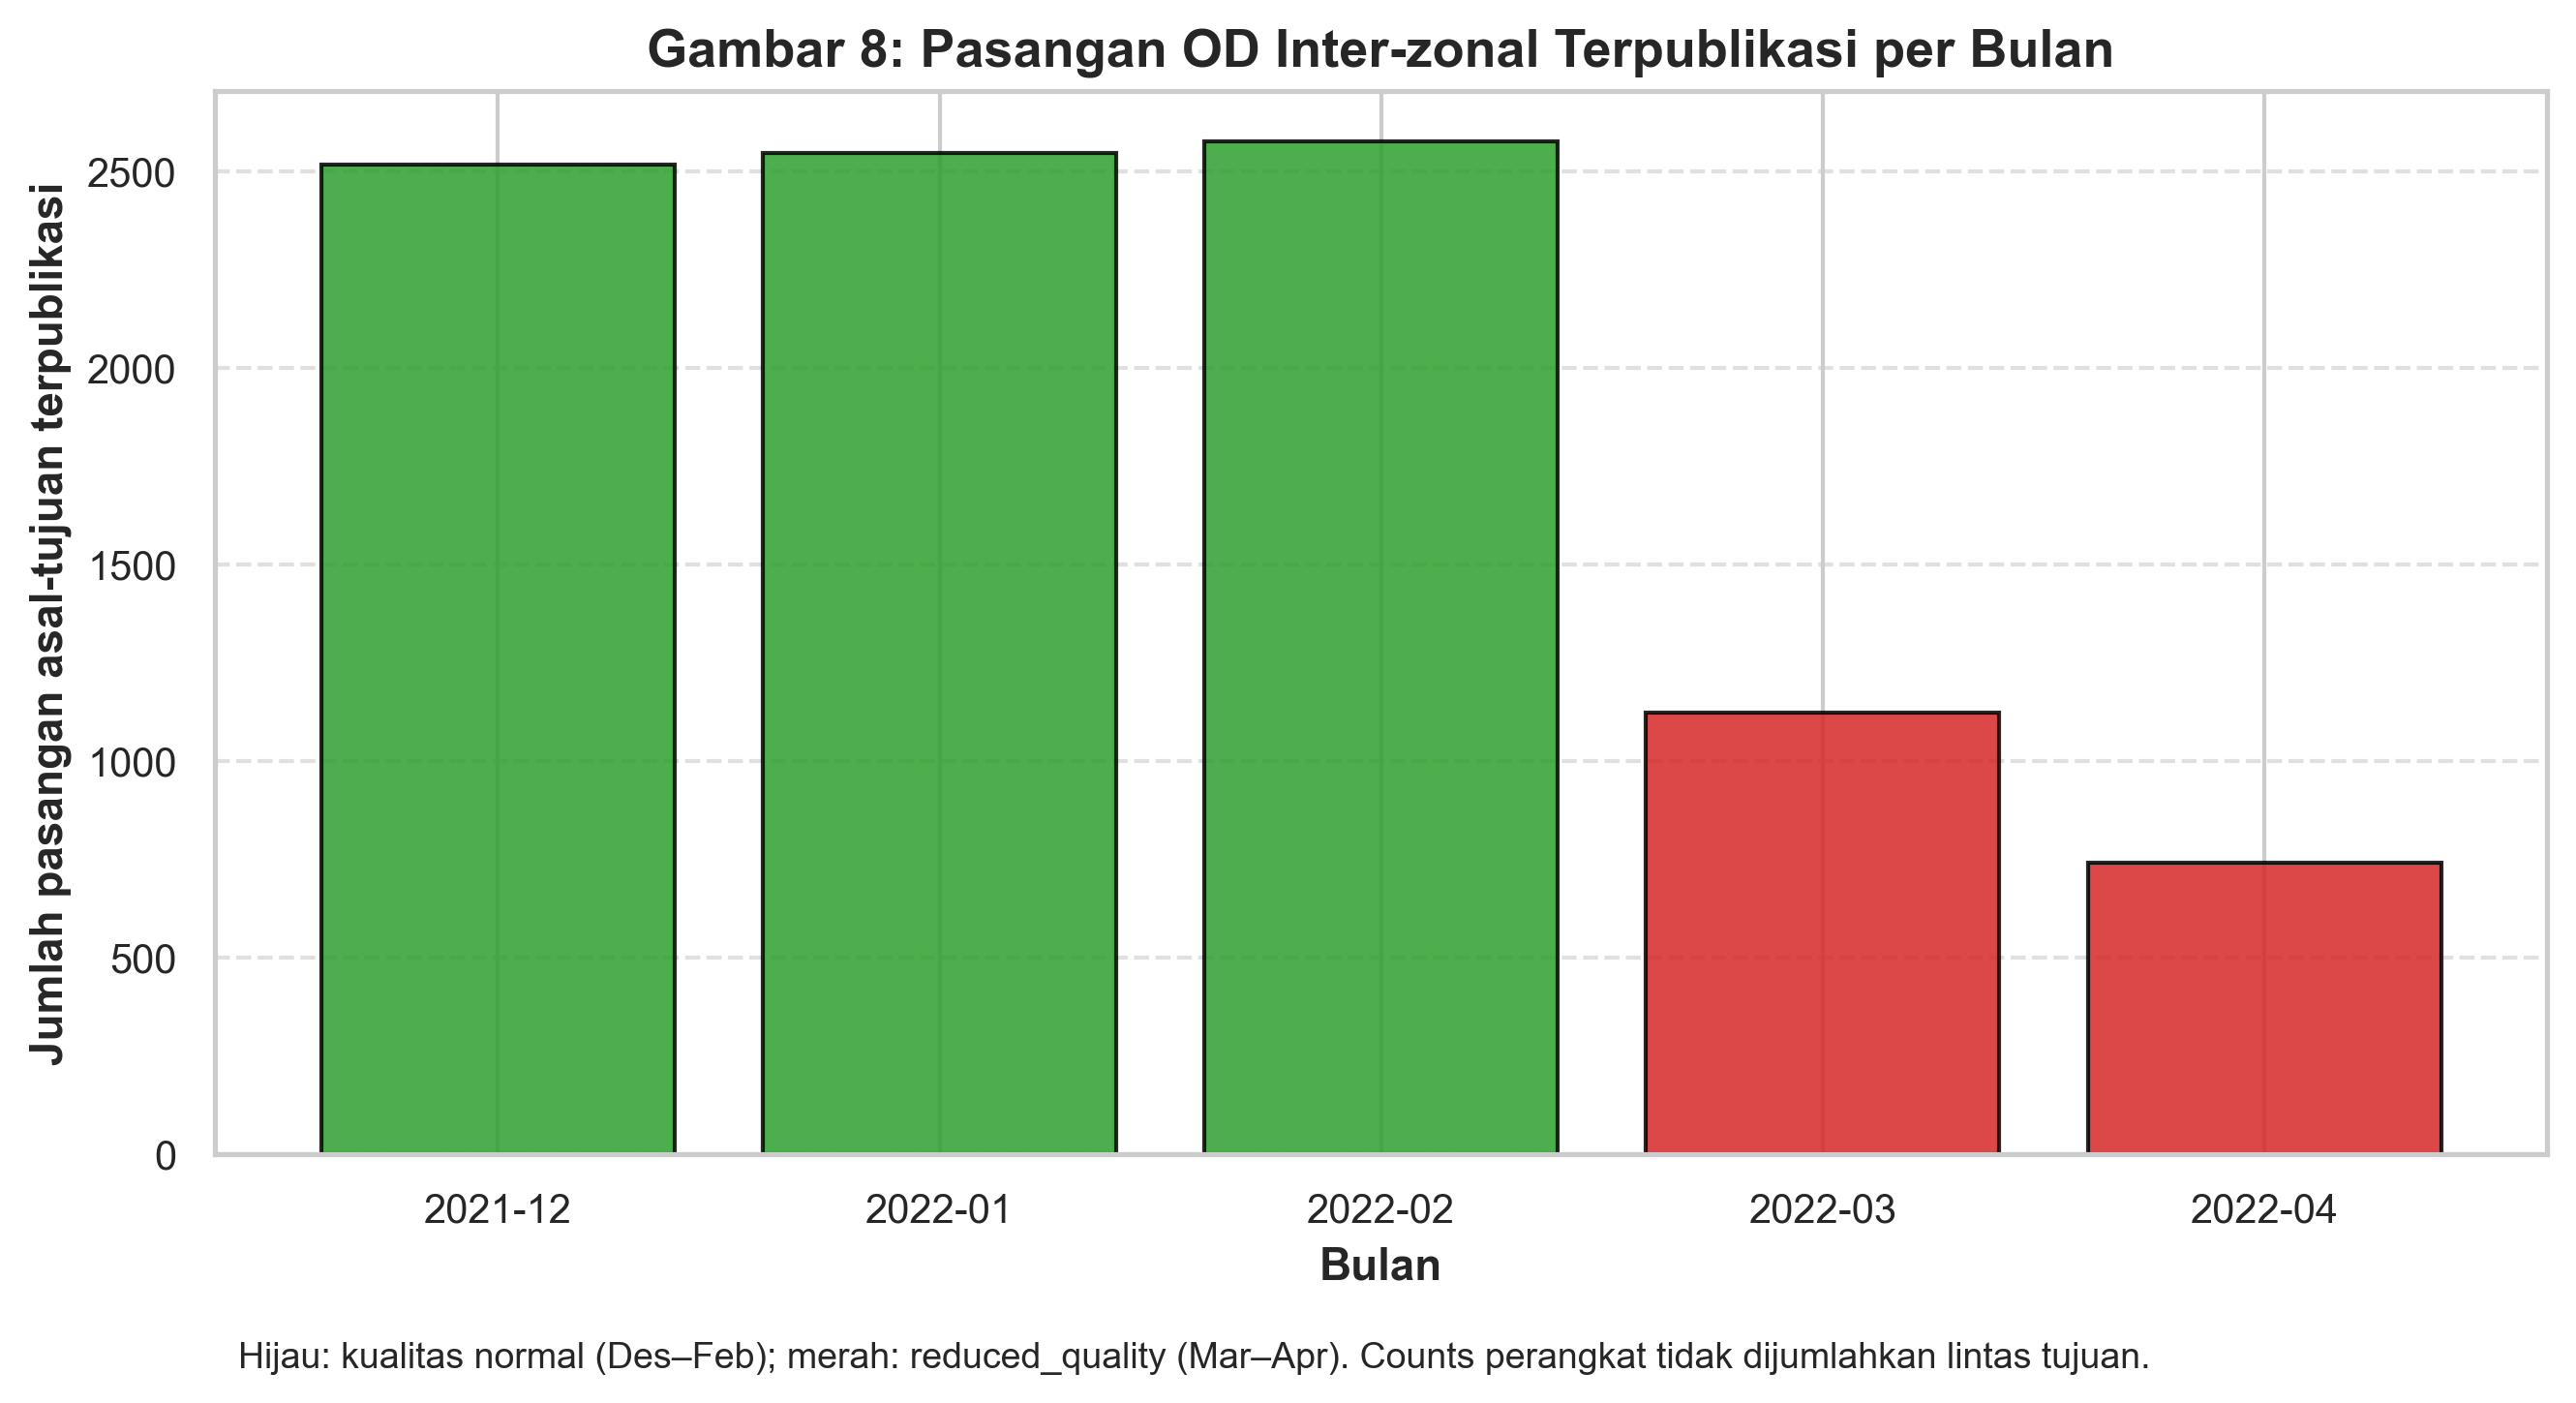

In [26]:
# 6.5 Perbandingan bulanan: hitungan pasangan OD terpublikasi dan median visitor count per pasangan
# n_maids tidak dijumlahkan lintas pasangan karena perangkat dapat mengunjungi beberapa tujuan.
od_all_inter = df_od_visits[df_od_visits["origin_code"] != df_od_visits["dest_code"]].copy()
monthly_od = od_all_inter.groupby(["month", "reduced_quality"]).agg(
    published_pairs=("n_maids", "size"),
    median_visitors_per_pair=("n_maids", "median")
).reset_index()

fig, ax1 = plt.subplots(figsize=(9, 5))
colors = ["#2ca02c" if not q else "#d62728" for q in monthly_od["reduced_quality"]]
ax1.bar(monthly_od["month"], monthly_od["published_pairs"], color=colors, edgecolor="black", alpha=0.85)
ax1.set_title("Gambar 8: Pasangan OD Inter-zonal Terpublikasi per Bulan")
ax1.set_xlabel("Bulan"); ax1.set_ylabel("Jumlah pasangan asal-tujuan terpublikasi")
ax1.grid(True, axis="y", linestyle="--", alpha=0.6)
ax1.text(0.01, -0.20, "Hijau: kualitas normal (Des–Feb); merah: reduced_quality (Mar–Apr). Counts perangkat tidak dijumlahkan lintas tujuan.", transform=ax1.transAxes, fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_perbandingan_od_bulanan_kualitas.png", bbox_inches="tight")
plt.show()
monthly_od.to_csv(TABLES_DIR / "rq2_ringkasan_kualitas_od_bulanan.csv", index=False)


### 6.6 Pembahasan RQ2
Peringkat tujuan pada Gambar 5 menunjukkan kapanewon dengan akumulasi visitor-count bulanan tertinggi selama bulan-bulan kualitas normal. Perangkat yang sama dapat dihitung pada beberapa tujuan dan bulan; angka akumulasi bukan jumlah perangkat unik selama seluruh periode dan bukan jumlah trip. Gunakan heatmap untuk melihat pasangan asal-tujuan, serta grafik pasangan terpublikasi untuk menunjukkan perubahan ketersediaan/kualitas bulanan. Hindari klaim sebab-akibat (misalnya komuter atau pengaruh kampus) tanpa data pendukung.


<a name="sec-7"></a>
## 7. Analisis RQ3: Pengaruh Normalisasi & Validasi Populasi BPS

**Pertanyaan Riset 3 (RQ3):**
> *Bagaimana hasilnya berubah setelah jumlah perangkat yang menjadi sampel diperhitungkan?*

Kita menguji dua aspek kritis:
1. **Normalisasi Arus OD:** Menghitung proporsi pengunjung terhadap total perangkat domisili yang aktif di siang hari ($n\_maids / n\_homed\_maids\_daytime$) menggunakan penyebut dari `od_origin_homes_monthly.csv`.
2. **Representativitas Sampel:** Menguji korelasi perangkat terestimasi rumah (`n_users`) terhadap populasi resmi penduduk dari BPS (`pop_actual`) pada seluruh 78 kapanewon.

In [27]:
# 7.1 Proporsi perangkat asal yang teramati pada setiap tujuan per bulan
od_norm = pd.merge(
    od_clean,
    df_od_origin[["month", "origin_code", "n_homed_maids_daytime"]],
    on=["month", "origin_code"], how="inner", validate="many_to_one"
)
# Penyebut kosong/0 tidak dapat dipakai. Ini mencerminkan supresi atau denominator tidak tersedia.
od_norm = od_norm.dropna(subset=["n_homed_maids_daytime"])
od_norm = od_norm[od_norm["n_homed_maids_daytime"] > 0].copy()
od_norm["proporsi_kunjungan"] = od_norm["n_maids"] / od_norm["n_homed_maids_daytime"]
# Rata-rata tidak berbobot antar pasangan asal-bulan yang teramati; bukan proporsi populasi DIY.
dest_norm = od_norm.groupby("dest_kapanewon")["proporsi_kunjungan"].agg(["mean", "count"]).reset_index()
dest_norm = dest_norm.sort_values("mean", ascending=False).reset_index(drop=True)
dest_norm.columns = ["Kapanewon Tujuan", "Rata-rata Proporsi Asal-Bulan", "Jumlah Pasangan Asal-Bulan"]
display(dest_norm.head(15))
dest_norm.to_csv(TABLES_DIR / "rq3_top15_destinasi_ternormalisasi.csv", index=False)


,Kapanewon Tujuan,Rata-rata Proporsi Asal-Bulan,Jumlah Pasangan Asal-Bulan
0,DEPOK,0.1038,212
1,BANGUNTAPAN,0.0823,200
2,RONGKOP,0.0815,9
3,UMBULHARJO,0.0797,173
4,GIRISUBO,0.0792,6
5,KASIHAN,0.0760,195
6,WONOSARI,0.0744,157
7,GONDOKUSUMAN,0.0732,171
8,GAMPING,0.0724,182
9,NGAGLIK,0.0656,185


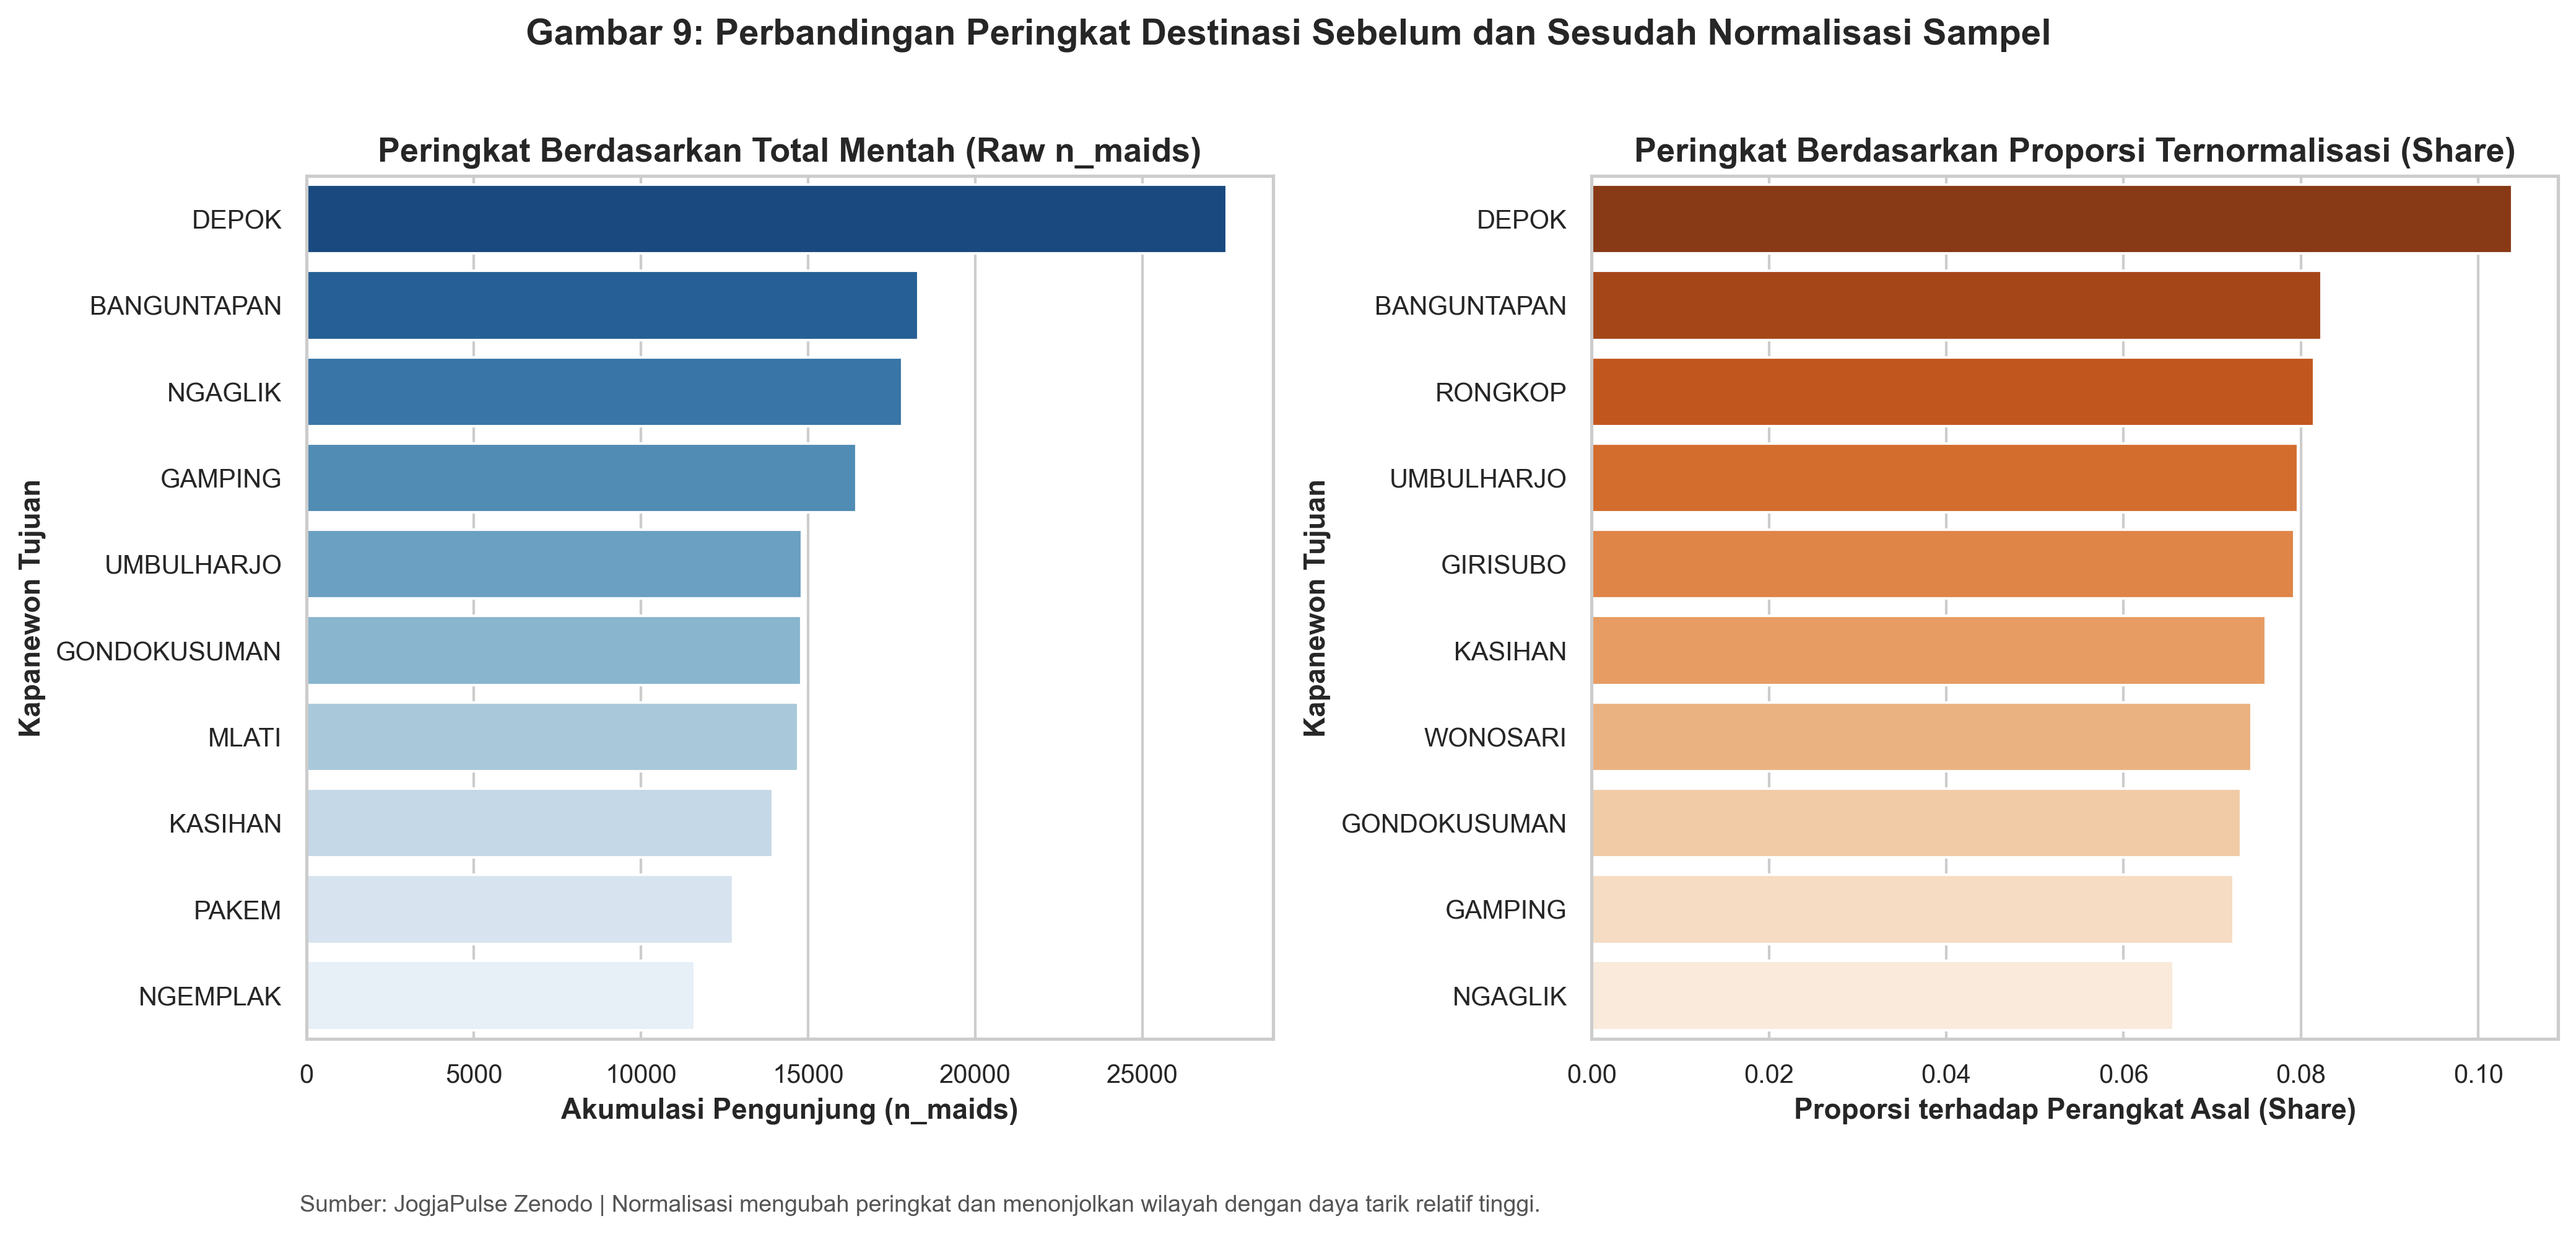

In [28]:
# 7.2 Visualisasi Gambar 9: Perbandingan Side-by-Side Peringkat Raw vs Normalized
top10_raw = top15_dest.head(10).copy()
top10_raw["Peringkat Mentah"] = range(1, 11)

top10_norm = dest_norm.head(10).copy()
top10_norm["Peringkat Ternormalisasi"] = range(1, 11)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=top10_raw, x="Total Pengunjung (n_maids)", y="Kapanewon Tujuan", ax=ax1, palette="Blues_r")
ax1.set_title("Peringkat Berdasarkan Total Mentah (Raw n_maids)", fontweight="bold")
ax1.set_xlabel("Akumulasi Pengunjung (n_maids)")

sns.barplot(data=top10_norm, x="Rata-rata Proporsi Asal-Bulan", y="Kapanewon Tujuan", ax=ax2, palette="Oranges_r")
ax2.set_title("Peringkat Berdasarkan Proporsi Ternormalisasi (Share)", fontweight="bold")
ax2.set_xlabel("Proporsi terhadap Perangkat Asal (Share)")

plt.suptitle("Gambar 9: Perbandingan Peringkat Destinasi Sebelum dan Sesudah Normalisasi Sampel", y=1.02, fontsize=14, fontweight="bold")
plt.figtext(0.12, -0.05, "Sumber: JogjaPulse Zenodo | Normalisasi mengubah peringkat dan menonjolkan wilayah dengan daya tarik relatif tinggi.", fontsize=9, color="#555555")
plt.savefig(FIGURES_DIR / "09_perbandingan_raw_vs_normalized_tujuan.png", bbox_inches="tight")
plt.show()


Pearson r=0.7234; jumlah kapanewon=78


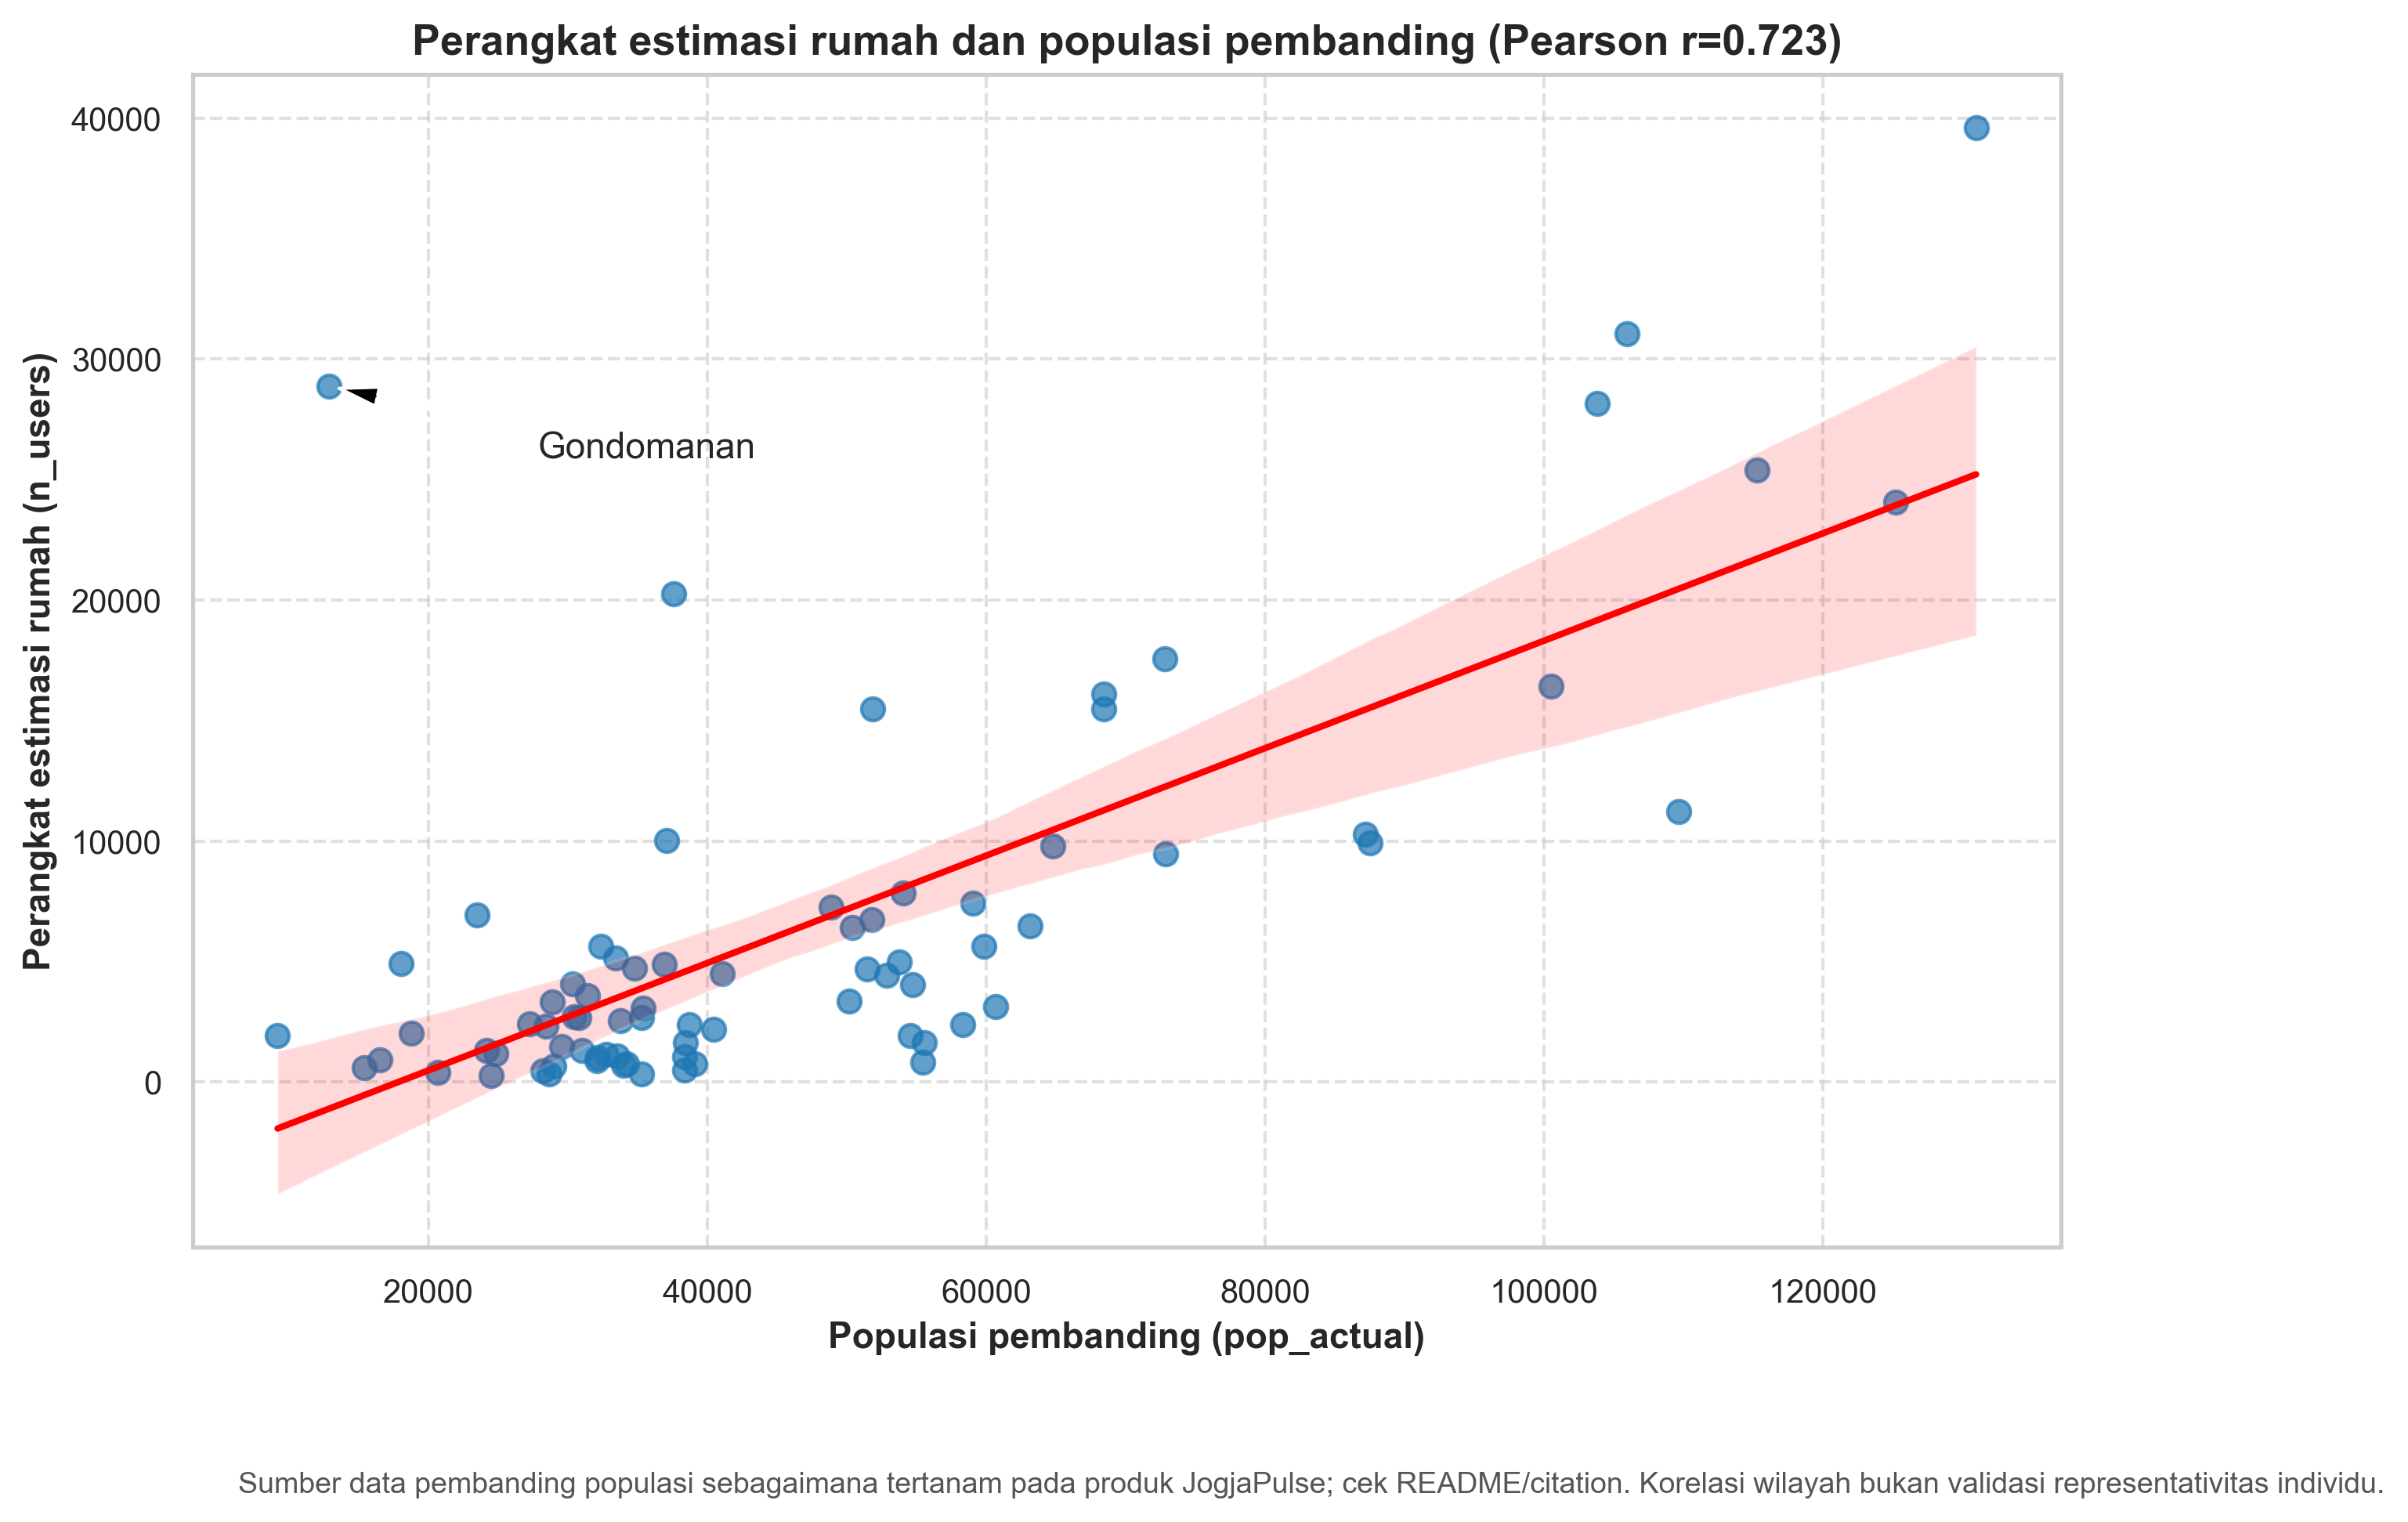

In [29]:
# 7.3 Hubungan perangkat estimasi rumah dan populasi pembanding
# Korelasi hanya menunjukkan hubungan antarwilayah; bukan bukti sampel representatif terhadap individu.
corr_pearson = df_home_pop["n_users"].corr(df_home_pop["pop_actual"])
print(f"Pearson r={corr_pearson:.4f}; jumlah kapanewon={df_home_pop.shape[0]}")
plt.figure(figsize=(9, 6))
sns.regplot(data=df_home_pop, x="pop_actual", y="n_users", color="#1f77b4",
            scatter_kws={"alpha": 0.7, "s": 50}, line_kws={"color": "red", "linewidth": 2})
plt.title(f"Perangkat estimasi rumah dan populasi pembanding (Pearson r={corr_pearson:.3f})")
plt.xlabel("Populasi pembanding (pop_actual)"); plt.ylabel("Perangkat estimasi rumah (n_users)")
gondo = df_home_pop[df_home_pop["KEC_KAPN"] == "GONDOMANAN"]
if not gondo.empty:
    row = gondo.iloc[0]
    plt.annotate("Gondomanan", xy=(row["pop_actual"], row["n_users"]),
                 xytext=(row["pop_actual"] + 15000, row["n_users"] - 3000),
                 arrowprops={"facecolor": "black", "shrink": 0.05, "width": 1, "headwidth": 6})
plt.grid(True, linestyle="--", alpha=0.6)
plt.figtext(0.12, -0.07, "Sumber data pembanding populasi sebagaimana tertanam pada produk JogjaPulse; cek README/citation. Korelasi wilayah bukan validasi representativitas individu.", fontsize=9, color="#555555")
plt.savefig(FIGURES_DIR / "10_scatter_perangkat_vs_populasi_bps.png", bbox_inches="tight")
plt.show()


### 7.4 Pembahasan RQ3
Normalisasi membagi visitor count untuk satu pasangan tujuan dengan perangkat asal yang teramati pada siang hari dalam bulan yang sama. Rata-rata tujuan di tabel merupakan rata-rata tidak berbobot atas pasangan asal-bulan yang tersedia; ini bukan estimasi probabilitas populasi DIY. Satu perangkat dapat berkunjung ke beberapa tujuan, sehingga proporsi lintas tujuan dapat melebihi 100%. Korelasi `n_users` dan `pop_actual` hanya menunjukkan asosiasi spasial pada tingkat kapanewon, bukan membuktikan sampel perangkat merepresentasikan setiap penduduk.


<a name="sec-8"></a>
## 8. Analisis Spasial: Sebaran Kehadiran pada Grid 500m (Resolusi Tinggi)

Sebagai visualisasi spasial pelengkap (*enrichment*), sel berikut memetakan koordinat *centroid* longitude dan latitude dari berkas `presence_cell500m_daily.csv` pada satu hari representatif di bulan Desember 2021.

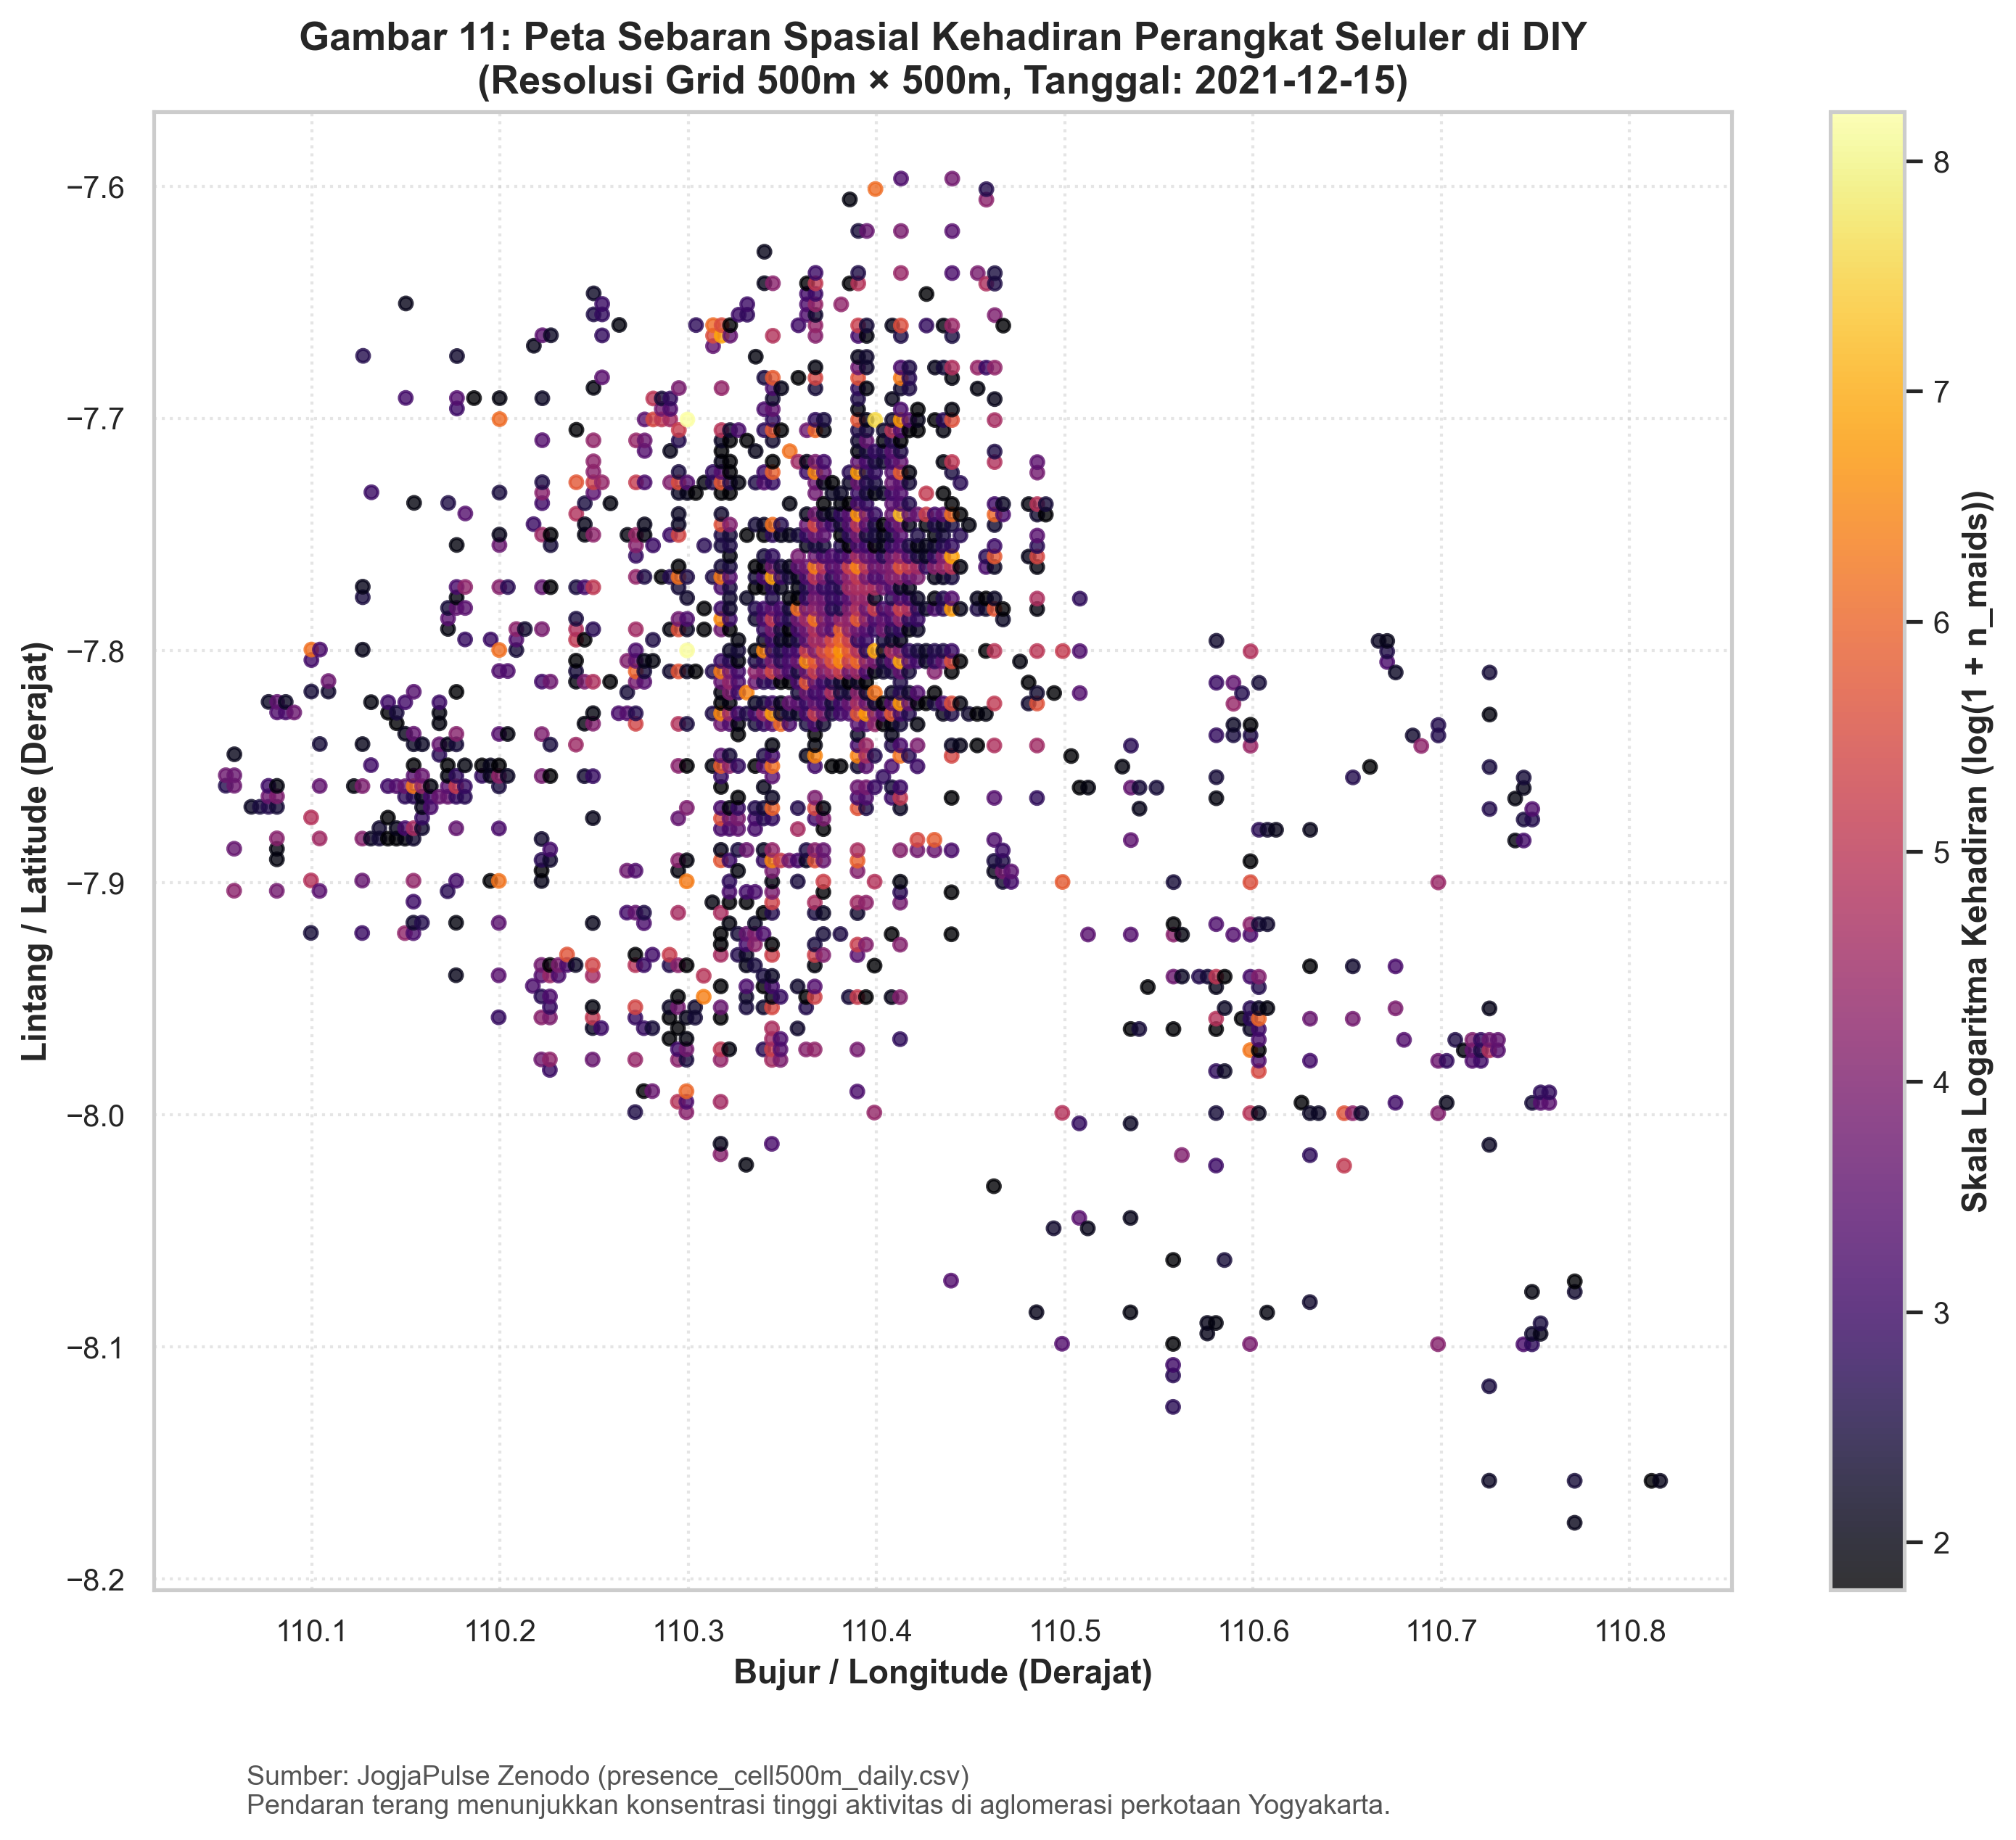

In [30]:
# 8.1 Visualisasi Gambar 11: Sebaran Spasial Perangkat pada Grid Sel 500m di DIY
# Mengambil sampel tanggal representatif (15 Desember 2021)
sample_date = "2021-12-15"
grid_day = df_pres_cell[df_pres_cell["date"] == sample_date]

plt.figure(figsize=(10, 8))
scatter = plt.scatter(grid_day["centroid_lon"], grid_day["centroid_lat"], 
                      c=np.log1p(grid_day["n_maids"]), cmap="inferno", s=18, alpha=0.8)
plt.colorbar(scatter, label="Skala Logaritma Kehadiran (log(1 + n_maids))")
plt.title(f"Gambar 11: Peta Sebaran Spasial Kehadiran Perangkat Seluler di DIY\n(Resolusi Grid 500m × 500m, Tanggal: {sample_date})")
plt.xlabel("Bujur / Longitude (Derajat)")
plt.ylabel("Lintang / Latitude (Derajat)")
plt.grid(True, linestyle=":", alpha=0.5)
plt.figtext(0.12, -0.05, "Sumber: JogjaPulse Zenodo (presence_cell500m_daily.csv)\nPendaran terang menunjukkan konsentrasi tinggi aktivitas di aglomerasi perkotaan Yogyakarta.", fontsize=9, color="#555555")
plt.savefig(os.path.join(FIGURES_DIR, "11_distribusi_spasial_grid500m.png"), bbox_inches="tight")
plt.show()

### 8.2 Pembahasan Pola Spasial Grid 500m
Peta sebaran sel 500m memperlihatkan konsentrasi intensitas perangkat yang sangat padat di kawasan aglomerasi perkotaan Yogyakarta (Kota Yogyakarta, Sleman selatan, dan Bantul utara), serta koridor jalan arteri utama (Jalan Solo, Jalan Palagan, Jalan Magelang). Sebaliknya, kawasan perbukitan Menoreh di barat dan karst Gunungkidul di timur memiliki densitas sel aktif yang renggang akibat supresi $k < 5$ pada daerah berpopulasi rendah.

<a name="sec-9"></a>
## 9. Evaluasi Kualitas Data, Mekanisme Supresi Privasi ($k=5$), & Limitasi

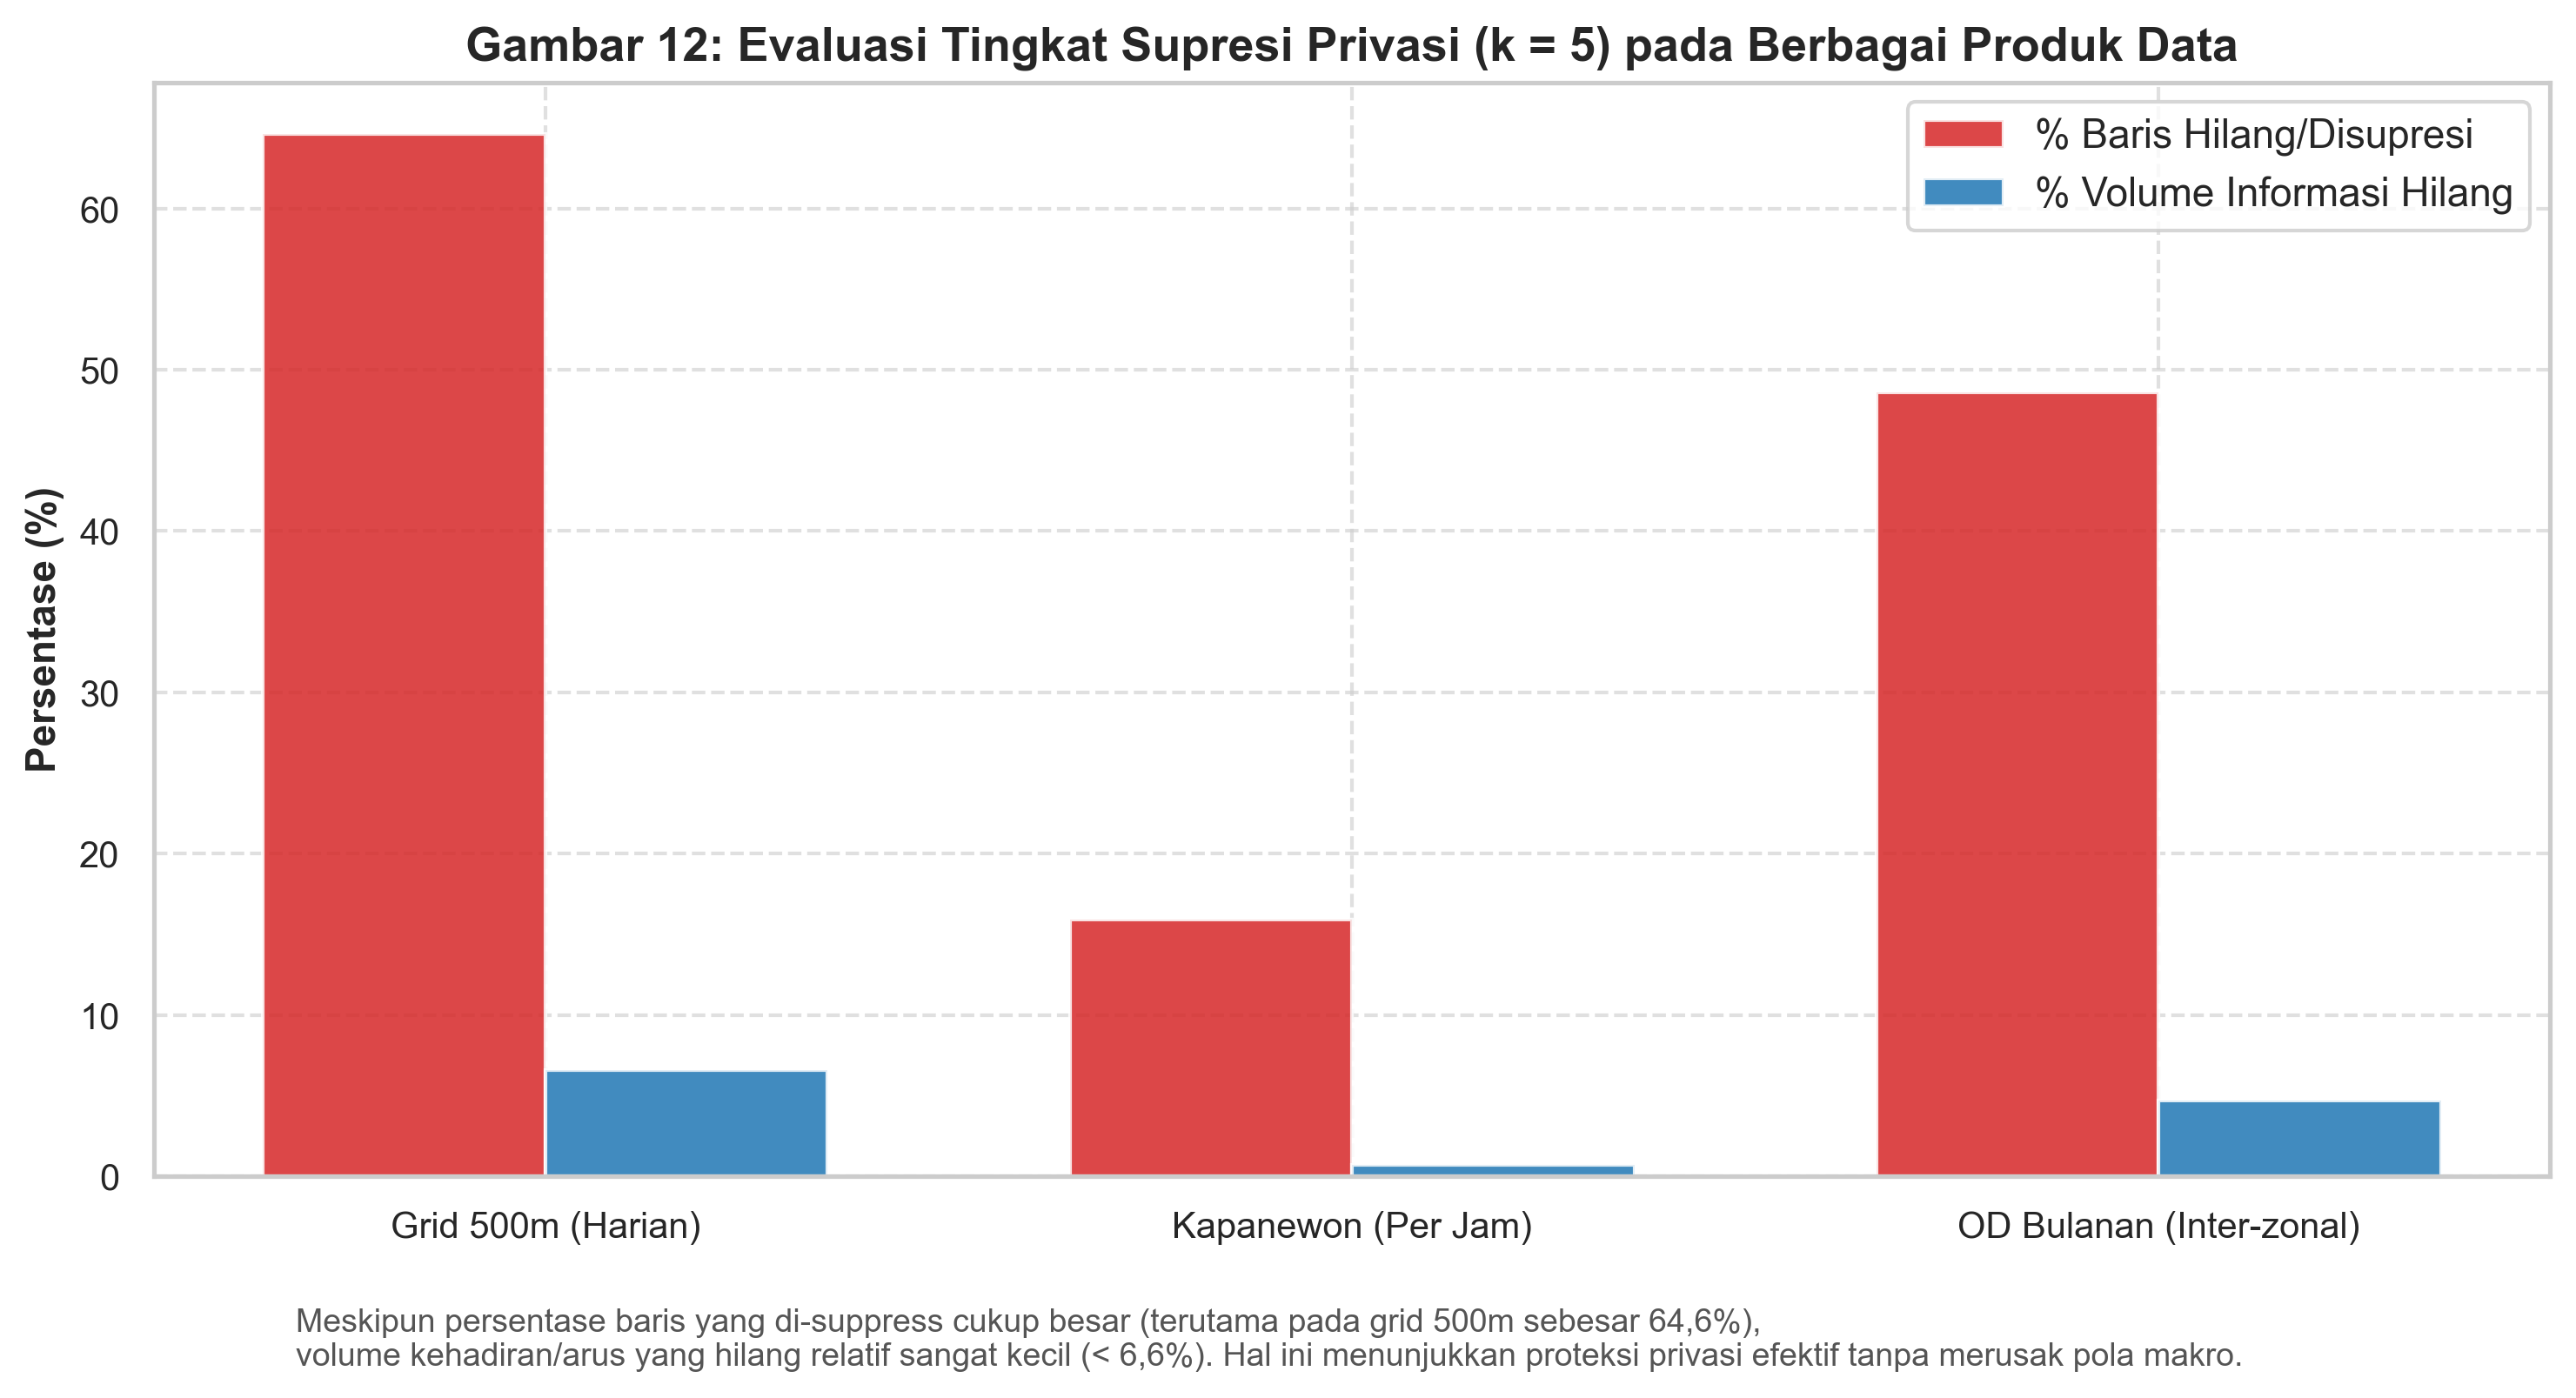

In [31]:
# 9.1 Visualisasi Gambar 12: Tingkat Supresi Baris dan Volume per Produk
supp_data = pd.DataFrame({
    "Produk": ["Grid 500m (Harian)", "Kapanewon (Per Jam)", "OD Bulanan (Inter-zonal)"],
    "% Baris Disupresi": [64.6, 15.9, 48.6],
    "% Volume Kehadiran/Arus Disupresi": [6.6, 0.7, 4.7]
})

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(supp_data))
width = 0.35

b1 = ax.bar(x - width/2, supp_data["% Baris Disupresi"], width, label="% Baris Hilang/Disupresi", color="#d62728", alpha=0.85)
b2 = ax.bar(x + width/2, supp_data["% Volume Kehadiran/Arus Disupresi"], width, label="% Volume Informasi Hilang", color="#1f77b4", alpha=0.85)

ax.set_title("Gambar 12: Evaluasi Tingkat Supresi Privasi (k = 5) pada Berbagai Produk Data")
ax.set_ylabel("Persentase (%)")
ax.set_xticks(x)
ax.set_xticklabels(supp_data["Produk"])
ax.legend(frameon=True)
ax.grid(True, linestyle="--", alpha=0.6)

plt.figtext(0.12, -0.06, "Meskipun persentase baris yang di-suppress cukup besar (terutama pada grid 500m sebesar 64,6%),\nvolume kehadiran/arus yang hilang relatif sangat kecil (< 6,6%). Hal ini menunjukkan proteksi privasi efektif tanpa merusak pola makro.", fontsize=9, color="#555555")
plt.savefig(os.path.join(FIGURES_DIR, "12_tingkat_supresi_dan_kualitas_data.png"), bbox_inches="tight")
plt.show()

### 9.2 Tujuh Batas Interpretasi Rekayasa Data (*Data Engineering Guardrails*)

Dalam menyajikan temuan proyek, kelompok menetapkan 7 batas kehati-hatian interpretasi:
1. **Perangkat $
eq$ Orang (*Devices $
eq$ People*):** Satu orang dapat memiliki lebih dari satu gawai aktif, atau sebaliknya satu gawai dipakai bersama.
2. **Sampel Non-Probabilistik:** Data berasal dari pengguna aplikasi yang mengaktifkan izin lokasi (*location-enabled apps*), bukan sampel acak representatif seluruh demografi masyarakat.
3. **Baris Hilang $
eq$ Nol (*Missing Rows $
eq$ Zero*):** Ketiadaan baris pada data terjadi akibat supresi privasi ($k < 5$), bukan berarti tidak ada kehadiran atau pergerakan sama sekali.
4. **Volume Sampel Berubah Sepanjang Waktu:** Penurunan dari ~87.000 ke ~9.000 perangkat per hari mencerminkan dinamika *feed* data aggregator, bukan penurunan mobilitas penduduk.
5. **Kunjungan Bulanan vs. Perjalanan (*Visitor vs. Trip Count*):** Nilai OD mencatat perangkat yang muncul setidaknya sekali di tujuan pada siang hari, bukan jumlah total perjalanan bolak-balik.
6. **Kualitas Menurun pada Maret–April 2022:** Data arus OD Maret–April ditandai `reduced_quality = True` dan dikeluarkan dari klaim kesimpulan utama.
7. **Pola Relatif Lebih Valid dibanding Angka Absolut:** Analisis harus bertumpu pada pangsa persentase (*share*) dan proporsi ternormalisasi, bukan penjumlahan angka mentah.

<a name="sec-10"></a>
## 10. Kesimpulan Sintesis & Rekomendasi

### 10.1 Menjawab pertanyaan riset

| Pertanyaan | Cara membaca hasil | Bukti |
|---|---|---|
| Bagaimana pola kehadiran berubah menurut jam/wilayah? | Jelaskan kurva pada baris kapanewon-jam yang terpublikasi. Sebutkan jam relatif tinggi/rendah berdasarkan grafik yang dihasilkan ulang; jangan menganggapnya total DIY. | Gambar 1–4 |
| Kapanewon mana menjadi tujuan kunjungan lintas wilayah? | Gunakan urutan pada tabel top destinasi. Angka merupakan akumulasi visitor-count bulanan per pasangan asal-tujuan selama periode terpilih; bukan orang unik sepanjang periode atau jumlah perjalanan. | Gambar 5–8 |
| Apa yang berubah setelah memperhitungkan perangkat asal? | Bandingkan peringkat mentah dan rata-rata proporsi asal-bulan yang tersedia. Nyatakan denominator dan bahwa rata-rata tidak berbobot serta hanya mencakup baris terpublikasi. | Gambar 9–10 |

Isi kesimpulan lisan/PPT memakai angka aktual dari tabel hasil setelah notebook dijalankan ulang. Jangan menyalin angka lama yang tertanam pada output atau narasi terdahulu.

### 10.2 Implikasi dan batas rekomendasi
Hasil dapat menjadi indikasi awal untuk pertanyaan perencanaan transportasi dan layanan, tetapi bukan bukti jumlah komuter, jumlah perjalanan, sebab-akibat, atau representasi seluruh penduduk. Rekomendasi kebijakan perlu dikonfirmasi dengan data transportasi, fasilitas, populasi, dan sumber eksternal yang terdokumentasi.


### 10.3 Referensi Data & Sitasi
1. **JogjaPulse Dataset (Sumber 1):** Widyawan (2026). *JogjaPulse: An Aggregated Spatio-Temporal Mobility Dataset for Yogyakarta, Indonesia*. Zenodo. DOI: [10.5281/zenodo.23157460](https://doi.org/10.5281/zenodo.23157460).
2. **Badan Pusat Statistik (Sumber 2):** BPS Provinsi D.I. Yogyakarta (2022). *Provinsi Daerah Istimewa Yogyakarta Dalam Angka 2022*, Katalog BPS: 1102001.34, ISSN: 0215-2169, Tabel 3.1.1 Penduduk per Kapanewon. URL: [https://yogyakarta.bps.go.id/](https://yogyakarta.bps.go.id/).
3. **Geoportal Pemda DIY (Batas Wilayah):** Pemerintah Daerah DIY (2023). *Batas Wilayah Administrasi Kalurahan dan Kapanewon DIY 2023*, [https://geoportal.jogjaprov.go.id/](https://geoportal.jogjaprov.go.id/).
